# 14 · Web 后端进阶（SpringBoot 原理 + Maven 高级）

本章整理两份飞书讲义：

- [SpringBoot 原理](https://heuqqdmbyk.feishu.cn/wiki/RM7gwxqcNi0mFUk7mIwcRYGznAe)：配置优先级、Bean 管理、起步依赖、自动配置和自定义 starter。
- [Maven 高级](https://heuqqdmbyk.feishu.cn/wiki/LrNiwwtqdiitzhkNyf8czV2gnIf)：分模块设计与开发、继承与聚合、私服和资源上传下载。

整理日期：2026-10-04。讲义中的原始代码、命令、配置、配图和提示均按原顺序保留；文中的“补充/勘误”用于解释实际开发中的边界和容易踩坑的地方。

## 本章学习路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 掌握配置覆盖 | `application.yml`、命令行参数、系统属性 | 能解释同名配置最终取值和启动参数来源 |
| 2 | 理解 Bean 管理 | `@Component`、`@Bean`、作用域、第三方 Bean | 能选择扫描、导入或手动声明 Bean 的方式 |
| 3 | 读懂自动配置 | 起步依赖、`@EnableAutoConfiguration`、条件注解 | 能从依赖和条件判断定位自动装配来源 |
| 4 | 写一个 starter | 自动配置模块、配置属性、条件装配 | 引入 starter 后只写配置即可得到 Bean |
| 5 | 拆分 Maven 项目 | 公共模块、业务模块、模块依赖 | 修改公共代码时能被多个模块复用 |
| 6 | 管理版本与构建 | `parent`、`dependencyManagement`、聚合 | 子模块版本统一，根工程一次完成构建 |
| 7 | 使用私服 | 发布、下载、镜像与认证 | 能区分本地仓库、远程仓库和私服职责 |

### 两条主线的关系

```text
Maven 依赖管理 -> 引入 Spring Boot starter -> 自动配置加载条件 Bean
       \                                      /
        -> 多模块工程共享版本、公共组件和构建生命周期
```

在前面十多天的课程当中，我们学习的都是web开发的技术使用，都是面向应用层面的，我们学会了怎么样去用。而我们今天所要学习的是web后端开发的最后一个篇章springboot原理篇，主要偏向于底层原理。

我们今天的课程安排包括这么三个部分：

1. 配置优先级

1. Bean的管理

1. 剖析Springboot的底层原理

## 配置优先级

> **补充｜配置覆盖的范围。** 讲义比较的是同一位置下的 `application.properties`、`application.yml` 和 `application.yaml`。实际 Spring Boot 还会合并 profile、外部配置目录、环境变量、系统属性和命令行参数；越靠后的属性源通常优先级越高。生产环境建议把密钥放在环境变量或密钥管理系统，不要提交到仓库。

在我们前面的课程当中，我们已经讲解了SpringBoot项目当中支持的三类配置文件：

- application.properties

- application.yml

- application.yaml

在SpringBoot项目当中，我们要想配置一个属性，可以通过这三种方式当中的任意一种来配置都可以，那么如果项目中同时存在这三种配置文件，且都配置了同一个属性，如：Tomcat端口号，到底哪一份配置文件生效呢？

- application.properties

```properties
server.port=8081
```

- application.yml

```yaml
server:
   port: 8082
```

- application.yaml

```yaml
server:
   port: 8082
```

我们启动SpringBoot程序，测试下三个配置文件中哪个Tomcat端口号生效：

- properties、yaml、yml三种配置文件同时存在。 配置好了，启动服务，测试一下：

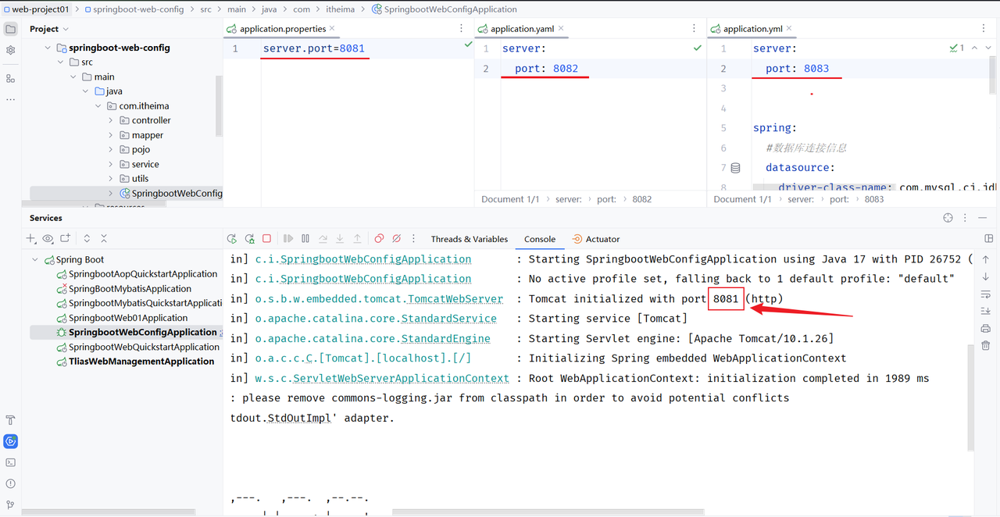

**讲义提示**

> properties、yaml、yml三种配置文件，优先级最高的是properties

- yaml、yml两种配置文件同时存在

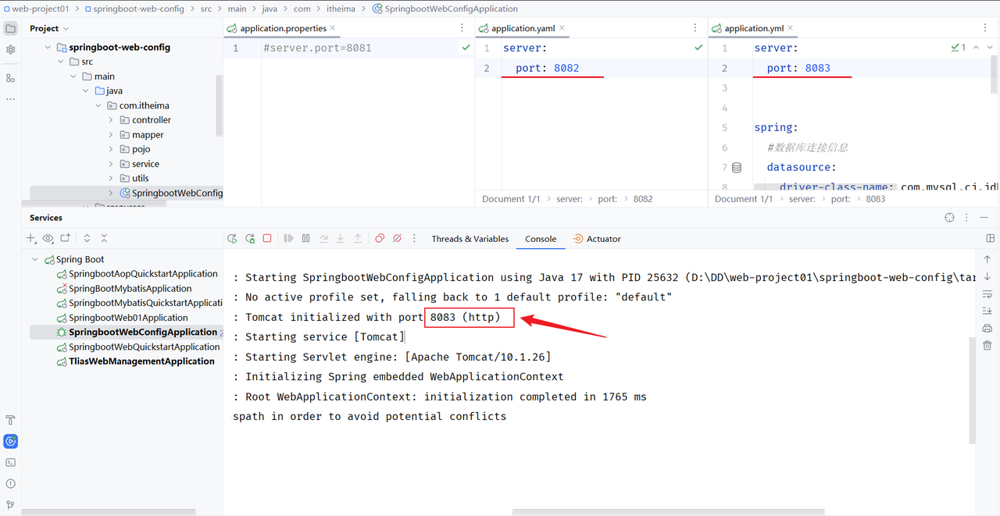

**讲义提示**

> yaml、yml 两种配置文件，优先级最高的是yml。

> 配置文件优先级排名（从高到低）：

> 1. properties配置文件

> 1. yml配置文件

> 1. yaml配置文件

**讲义提示**

> 注意事项：虽然springboot支持多种格式配置文件，但是在项目开发时，推荐统一使用一种格式的配置。（yml是主流）

在SpringBoot项目当中除了以上3种配置文件外，SpringBoot为了增强程序的扩展性，除了支持配置文件的配置方式以外，还支持另外两种常见的配置方式：

1. Java系统属性配置 （格式： -Dkey=value）

```yaml
-Dserver.port=9000
```

1. 命令行参数 （格式：--key=value）

```yaml
--server.port=10010
```

那在idea当中运行程序时，如何来指定Java系统属性和命令行参数呢？

- 编辑启动程序的配置信息

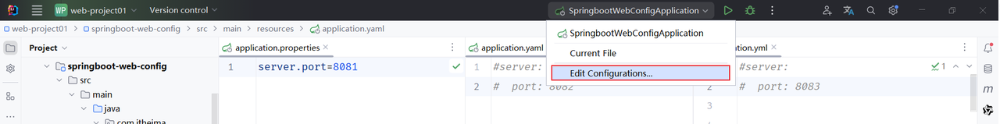

打开之后，选择 Modify options , 选择 Add VM options, Program arguments

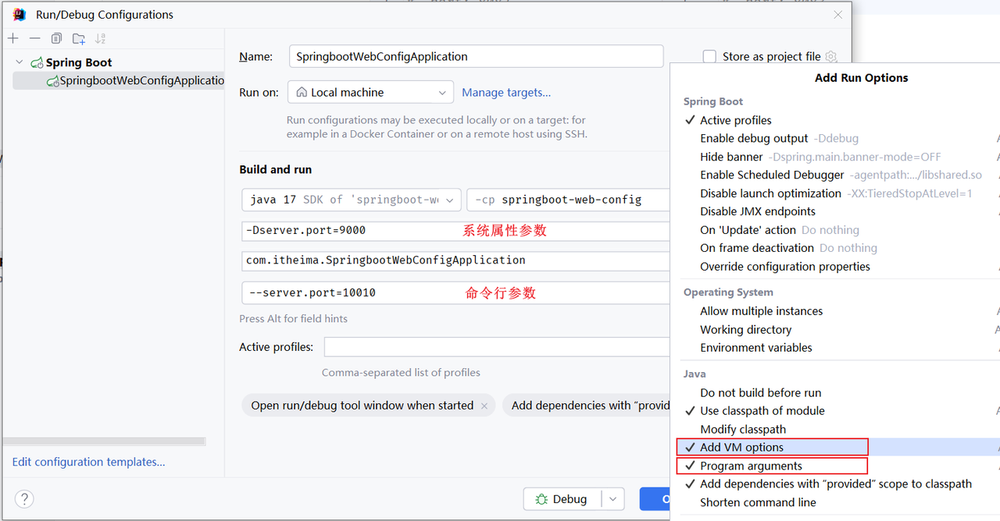

重启服务，同时配置Tomcat端口(application.properties、系统属性、命令行参数)，测试哪个Tomcat端口号生效：

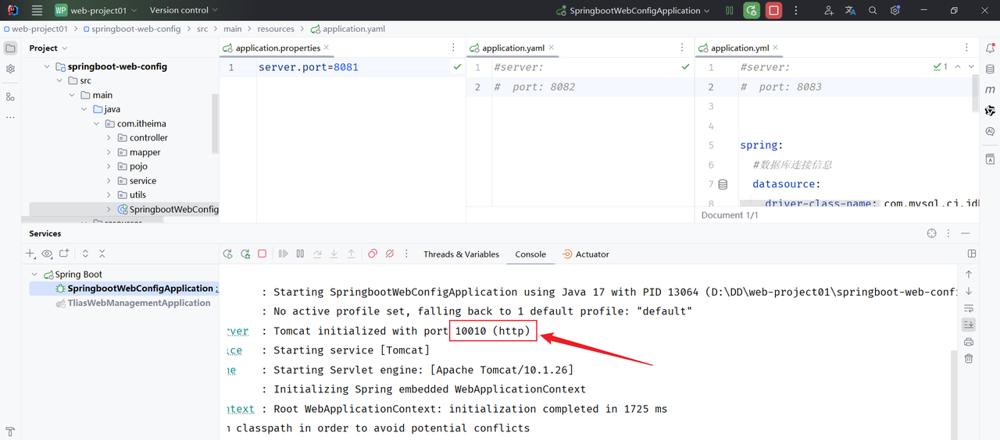

**讲义提示**

> 说明，命令行参数的优先级时最高的，同时配置的情况下，命令行参数的配置项生效。

删除命令行参数配置，重启SpringBoot服务：

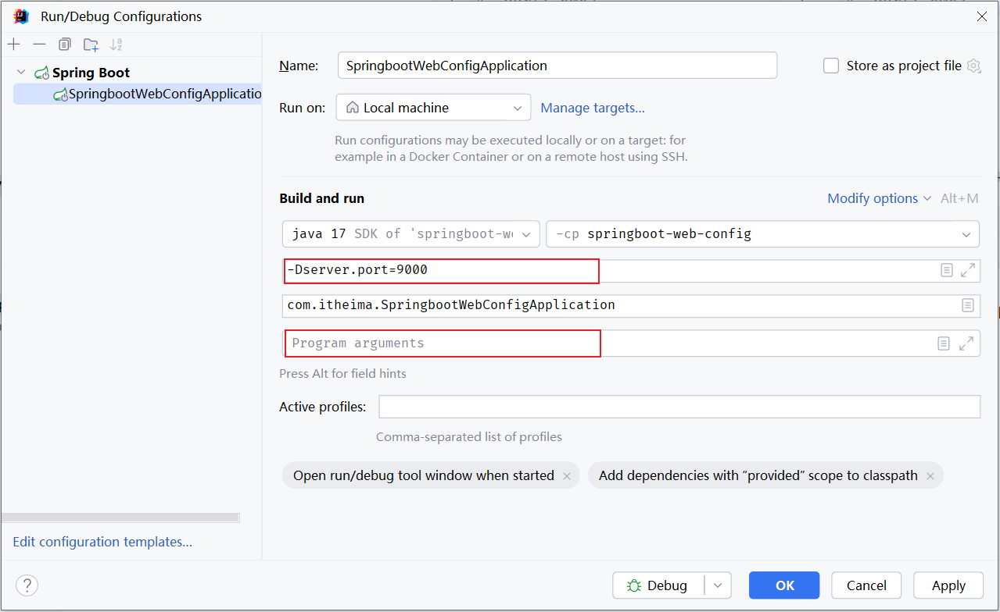

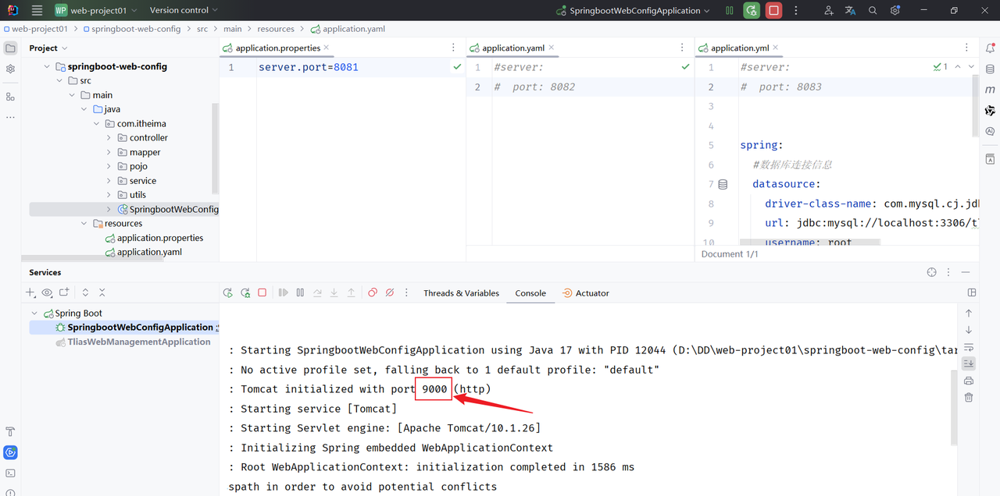

**讲义提示**

> 五种配置方式的优先级： 命令行参数 >  系统属性参数 > properties参数 > yml参数 > yaml参数

思考：如果项目已经打包上线了，这个时候我们又如何来设置Java系统属性和命令行参数呢？

```yaml
java -Dserver.port=9000 -jar XXXXX.jar --server.port=10010
```

下面我们来演示下打包程序运行时指定Java系统属性和命令行参数：

1. 执行maven打包指令package，把项目打成jar文件

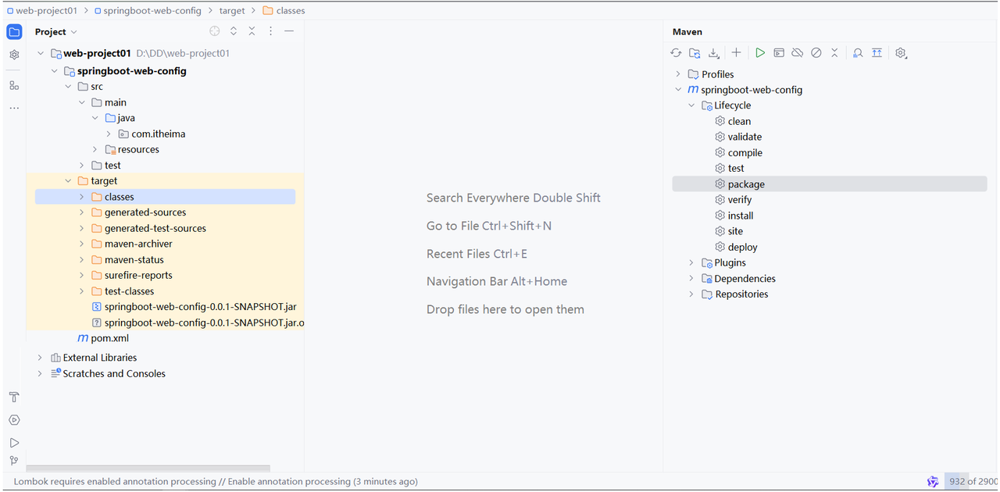

1. 使用命令：java -jar 方式运行jar文件程序。

同时设置Java系统属性和命令行参数

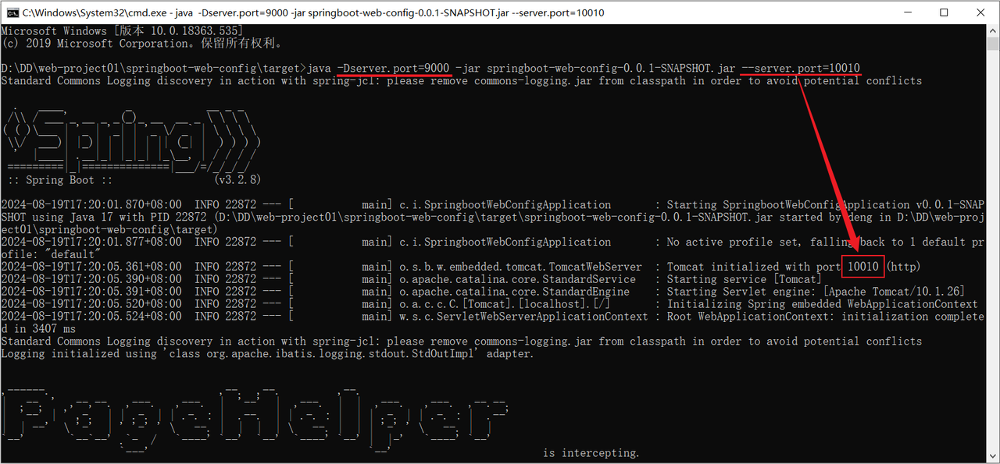

仅设置Java系统属性

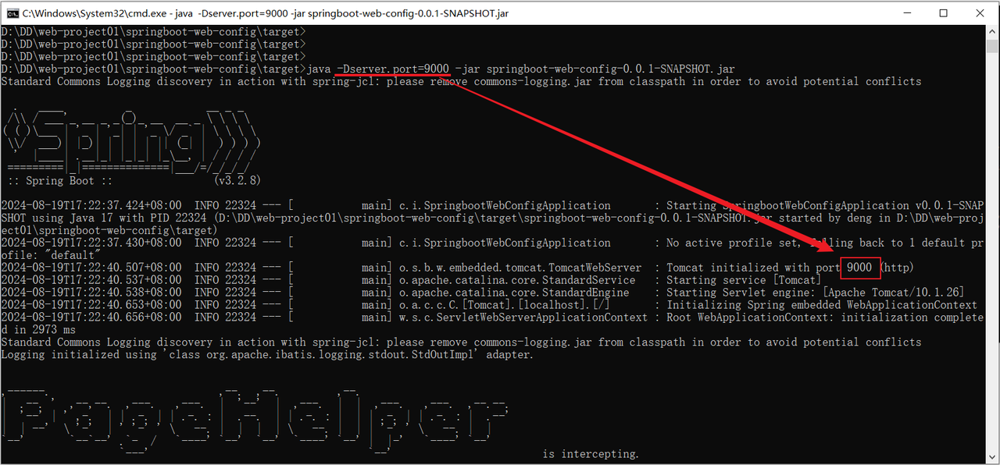

**讲义提示**

> 注意事项：

> - Springboot项目进行打包时，需要引入插件 spring-boot-maven-plugin (基于官网骨架创建项目，会自动添加该插件)

在SpringBoot项目当中，常见的属性配置方式有5种， 3种配置文件，加上2种外部属性的配置(Java系统属性、命令行参数)。通过以上的测试，我们也得出了优先级(从低到高)：

- application.yaml（忽略）

- application.yml

- application.properties

- java系统属性（-Dxxx=xxx）

- 命令行参数（--xxx=xxx）

## Bean的管理

> **补充｜Bean 注册方式。** `@Component` 及其派生注解依赖组件扫描；`@Bean` 适合注册第三方类或需要显式组装的对象；`@Import` 可导入配置类。Bean 的名字、条件和作用域都会影响注入结果，遇到多个候选对象时使用 `@Primary` 或 `@Qualifier` 明确选择。

在前面的课程当中，我们已经讲过了我们可以通过Spring当中提供的注解@Component以及它的三个衍生注解（@Controller、@Service、@Repository）来声明IOC容器中的bean对象，同时我们也学习了如何为应用程序注入运行时所需要依赖的bean对象，也就是依赖注入DI。

我们今天主要学习IOC容器中Bean的其他使用细节，主要学习以下三方面：

1. bean的作用域配置

1. 管理第三方的bean对象

接下来我们先来学习第一方面，Bean的作用域。

### Bean的作用域

> **补充｜作用域选择。** `singleton` 是默认作用域，容器中只有一个实例；`prototype` 每次获取都会创建新对象，但销毁回调由调用方负责。Web 项目还常用 `request`、`session` 等作用域，使用它们时要确保运行在对应的 Web 上下文中。

在前面我们提到的IOC容器当中，默认bean对象是单例的 (只有一个实例对象)。在Spring中支持五种作用域，后三种在web环境才生效：

*此处为飞书电子表格嵌入，离线笔记保留其位置。*

> **说明｜外部表格。** 讲义此处嵌入了飞书电子表格组件，原始快照只提供表格 token，无法离线展开其单元格内容；相关文字说明和截图已保留在相邻内容中。

知道了bean的5种作用域了，我们要怎么去设置一个bean的作用域呢？

- 可以借助Spring中的@Scope注解来进行配置作用域

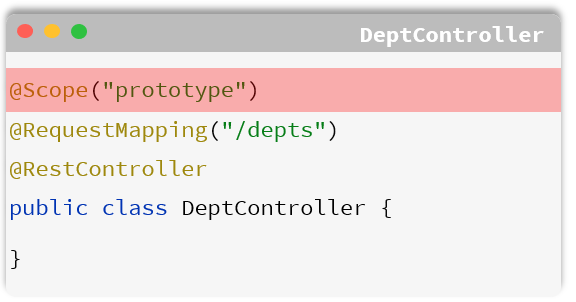

1). 测试一

- 控制器

```java
//默认bean的作用域为：singleton (单例)
@RestController
@RequestMapping("/depts")
public class DeptController {

    @Autowired
    private DeptService deptService;

    public DeptController(){
        System.out.println("DeptController constructor ....");
    }

    //省略其他代码...
}
```

- 测试类

```java
@SpringBootTest
class SpringbootWebConfig2ApplicationTests {

    @Autowired
    private ApplicationContext applicationContext; //IOC容器对象

    //bean的作用域
    @Test
    public void testScope(){
        for (int i = 0; i < 10; i++) {
            DeptController deptController = applicationContext.getBean(DeptController.class);
            System.out.println(deptController);
        }
    }
}
```

重启SpringBoot服务，运行测试方法，查看控制台打印的日志：

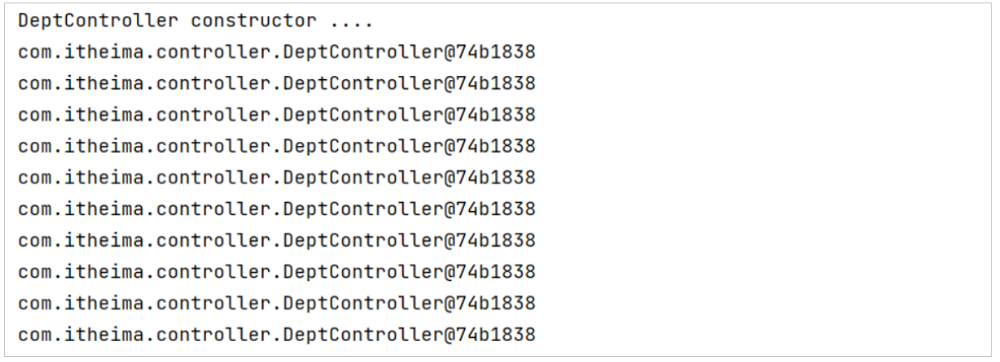

**讲义提示**

> 注意事项：

> - IOC容器中的bean默认使用的作用域：singleton (单例)

> - 默认singleton的bean，在容器启动时被创建，可以使用@Lazy注解来延迟初始化(延迟到第一次使用时)

2). 测试二

修改控制器DeptController代码：

```java
@Scope("prototype") //bean作用域为非单例
@RestController
@RequestMapping("/depts")
public class DeptController {

    @Autowired
    private DeptService deptService;

    public DeptController(){
        System.out.println("DeptController constructor ....");
    }

    //省略其他代码...
}
```

重启SpringBoot服务，再次执行测试方法，查看控制吧打印的日志：

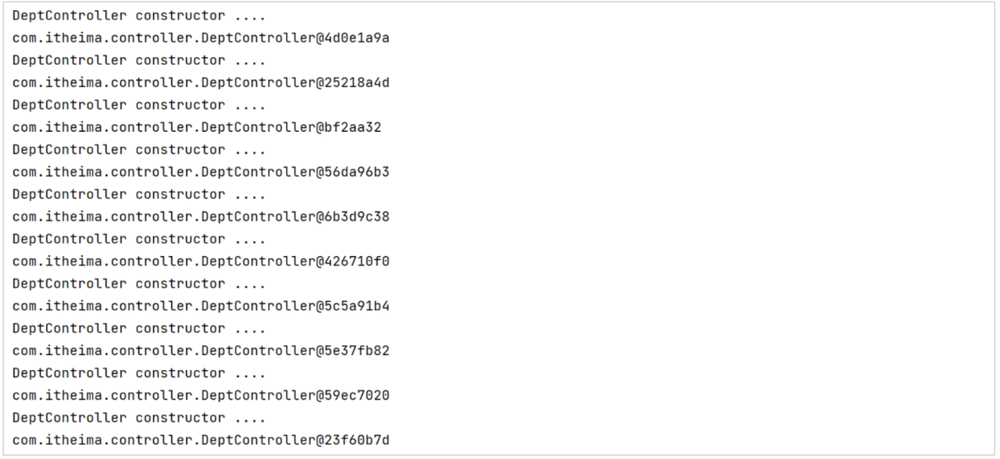

**讲义提示**

> 注意事项：

> - prototype的bean，每一次使用该bean的时候都会创建一个新的实例

> - 实际开发当中，绝大部分的Bean是单例的，也就是说绝大部分Bean不需要配置scope属性

**讲义提示**

> - 默认singleton的bean，在容器启动时被创建，可以使用@Lazy注解来延迟初始化（延迟到第一次使用时）

> - prototype的bean，每一次使用该bean的时候都会创建一个新的实例。

> - 实际开发当中，绝大部分的bean是单例的，也就是说绝大部分bean不需要配置scope属性。

### 第三方Bean

> **补充｜第三方 Bean 的生命周期。** 给第三方类配置 `@Bean` 时，可以在方法参数中声明它依赖的其他 Bean，Spring 会按类型注入。配置方法应保持幂等，避免在方法体中重复创建连接池、线程池等重量对象。

学习完bean的获取、bean的作用域之后，接下来我们再来学习第三方bean的配置。

之前我们所配置的bean，像controller、service，dao三层体系下编写的类，这些类都是我们在项目当中自己定义的类(自定义类)。当我们要声明这些bean，也非常简单，我们只需要在类上加上@Component以及它的这三个衍生注解（@Controller、@Service、@Repository），就可以来声明这个bean对象了。

但是在我们项目开发当中，还有一种情况就是这个类它不是我们自己编写的，而是我们引入的第三方依赖当中提供的，那么此时我们是无法使用 @Component 及其衍生注解来声明bean的，此时就需要使用@Bean注解来声明bean 了。

演示1：

- 在启动类中直接声明这个Bean。比如：我们可以将我们之前使用的阿里云OSS操作的工具类，基于@Bean注解的方式来声明Bean。

```java
import com.itheima.utils.AliyunOSSOperator;
import com.itheima.utils.AliyunOSSProperties;
import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.boot.web.servlet.ServletComponentScan;
import org.springframework.context.annotation.Bean;
import org.springframework.scheduling.annotation.EnableScheduling;

@ServletComponentScan
@EnableScheduling
@SpringBootApplication
public class TliasWebManagementApplication {

    public static void main(String[] args) {
        SpringApplication.run(TliasWebManagementApplication.class, args);
    }

    @Bean
    public AliyunOSSOperator aliyunOSSOperator(AliyunOSSProperties ossProperties) {
        return new AliyunOSSOperator(ossProperties);
    }
}
```

- 测试：

```java
package com.itheima;

import cn.hutool.core.io.FileUtil;
import com.itheima.utils.AliyunOSSOperator;
import org.junit.jupiter.api.Test;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.boot.test.context.SpringBootTest;

import java.io.File;
import java.util.List;
import java.util.Set;

@SpringBootTest
class TliasWebManagementApplicationTests {

    @Autowired
    private AliyunOSSOperator aliyunOSSOperator;

    @Test
    void testUploadFiles() throws Exception {
        // 上传文件, 本地文件 C:\Users\deng\Pictures\6.jpg
        byte[] content = FileUtil.readBytes(new File("C:\\Users\\deng\\Pictures\\6.jpg"));
        String url = aliyunOSSOperator.upload(content, "6.jpg");
        System.out.println(url);
    }

    @Test
    void testListFiles() throws Exception {
        // 获取文件列表
        List<String> objectNameList = aliyunOSSOperator.listFiles();
        objectNameList.forEach(System.out::println);
    }

    @Test
    void testDelFiles() throws Exception {
        // 删除文件
        aliyunOSSOperator.deleteFile("2024/06/43b48632-3a05-4e1d-a00d-96f2d57b2a84.jpg");
    }

}
```

演示2：

若要管理的第三方 bean 对象，建议对这些bean进行集中分类配置，可以通过 @Configuration 注解声明一个配置类。【推荐】

```java
package com.itheima.config;

import com.itheima.utils.AliyunOSSOperator;
import com.itheima.utils.AliyunOSSProperties;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;

@Configuration
public class OSSConfig {
    @Bean
    public AliyunOSSOperator aliyunOSSOperator(AliyunOSSProperties ossProperties) {
        return new AliyunOSSOperator(ossProperties);
    }
}
```

**讲义提示**

> - 通过@Bean注解的name 或 value属性可以声明bean的名称，如果不指定，默认bean的名称就是方法名。

> - 如果第三方bean需要依赖其他bean对象，直接在bean定义方法中设置形参即可，容器会根据类型自动装配。

## SpringBoot原理

> **补充｜启动入口。** `@SpringBootApplication` 组合了配置类、组件扫描和自动配置三个能力。自动配置的目标是提供合理默认值，项目自身定义的 Bean 通常会通过条件注解让默认 Bean 退让。排查启动行为时可打开条件评估报告，查看哪些配置匹配或未匹配。

经过前面10多天课程的学习，大家也会发现基于SpringBoot进行web程序的开发是非常简单、非常高效的。

SpringBoot使我们能够集中精力地去关注业务功能的开发，而不用过多地关注框架本身的配置使用。而我们前面所讲解的都是面向应用层面的技术，接下来我们开始学习SpringBoot的原理，这部分内容偏向于底层的原理分析。

在剖析SpringBoot的原理之前，我们先来快速回顾一下我们前面所讲解的Spring家族的框架。

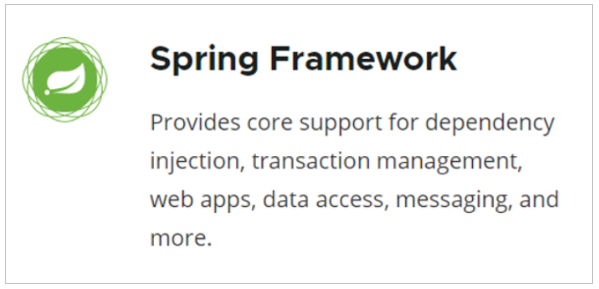

Spring是目前世界上最流行的Java框架，它可以帮助我们更加快速、更加容易的来构建Java项目。而在Spring家族当中提供了很多优秀的框架，而所有的框架都是基于一个基础框架的SpringFramework(也就是Spring框架)。而前面我们也提到，如果我们直接基于Spring框架进行项目的开发，会比较繁琐。

这个繁琐主要体现在两个地方：

1. 在pom.xml中依赖配置比较繁琐，在项目开发时，需要自己去找到对应的依赖，还需要找到依赖它所配套的依赖以及对应版本，否则就会出现版本冲突问题。

1. 在使用Spring框架进行项目开发时，需要在Spring的配置文件中做大量的配置，这就造成Spring框架入门难度较大，学习成本较高。

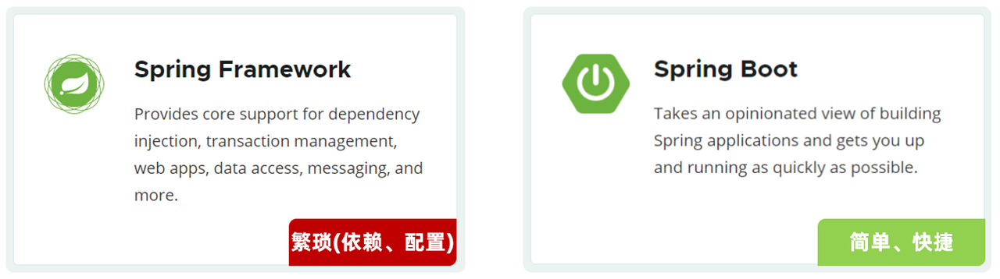

**讲义提示**

> - 基于Spring存在的问题，官方在Spring框架4.0版本之后，又推出了一个全新的框架：SpringBoot。

> - 通过 SpringBoot来简化Spring框架的开发(是简化不是替代)。我们直接基于SpringBoot来构建Java项目，会让我们的项目开发更加简单，更加快捷。

SpringBoot框架之所以使用起来更简单更快捷，是因为SpringBoot框架底层提供了两个非常重要的功能：一个是起步依赖，一个是自动配置。

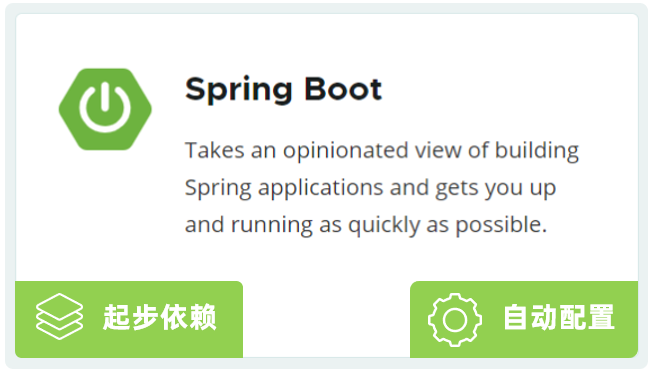

**讲义提示**

> - 通过SpringBoot所提供的起步依赖，就可以大大的简化pom文件当中依赖的配置，从而解决了Spring框架当中依赖配置繁琐的问题。

> - 通过自动配置的功能就可以大大的简化框架在使用时bean的声明以及bean的配置。我们只需要引入程序开发时所需要的起步依赖，项目开发时所用到常见的配置都已经有了，我们直接使用就可以了。

简单回顾之后，接下来我们来学习下SpringBoot的原理。其实学习SpringBoot的原理就是来解析SpringBoot当中的起步依赖与自动配置的原理。我们首先来学习SpringBoot当中起步依赖的原理。

### 起步依赖

> **补充｜起步依赖的边界。** starter 通常只负责聚合一组经过验证的依赖版本；它不会凭名字直接执行 Java 代码。真正的自动装配来自对应的 auto-configuration 模块以及 Spring Boot 启动时加载的配置声明。

假如我们没有使用SpringBoot，用的是Spring框架进行web程序的开发，此时我们就需要引入web程序开发所需要的一些依赖。

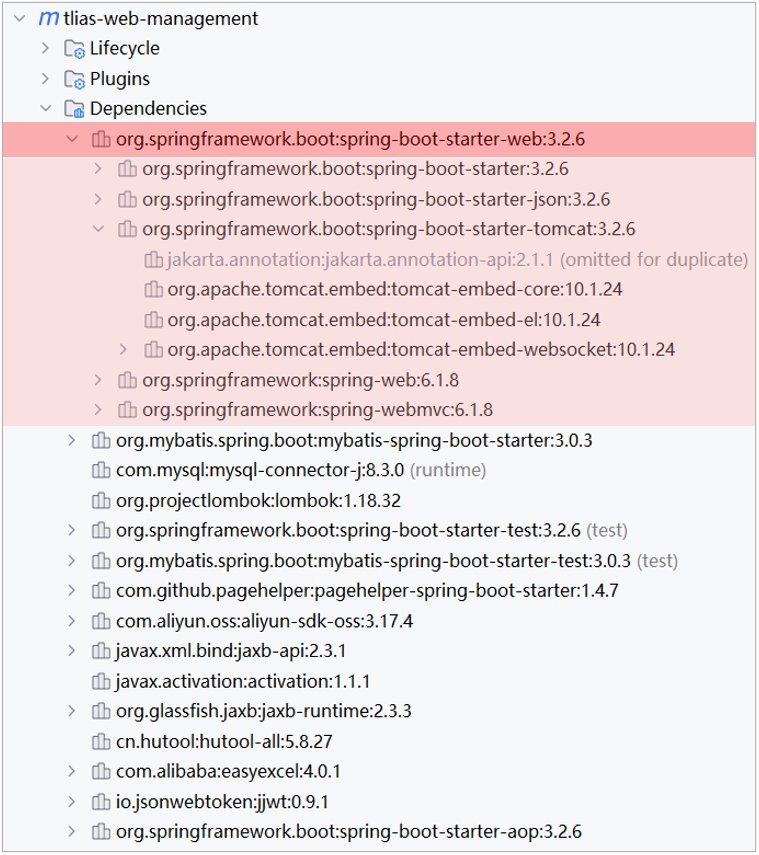

当我们引入了 spring-boot-starter-web 之后，maven会通过依赖传递特性，将web开发所需的常见依赖都传递下来。

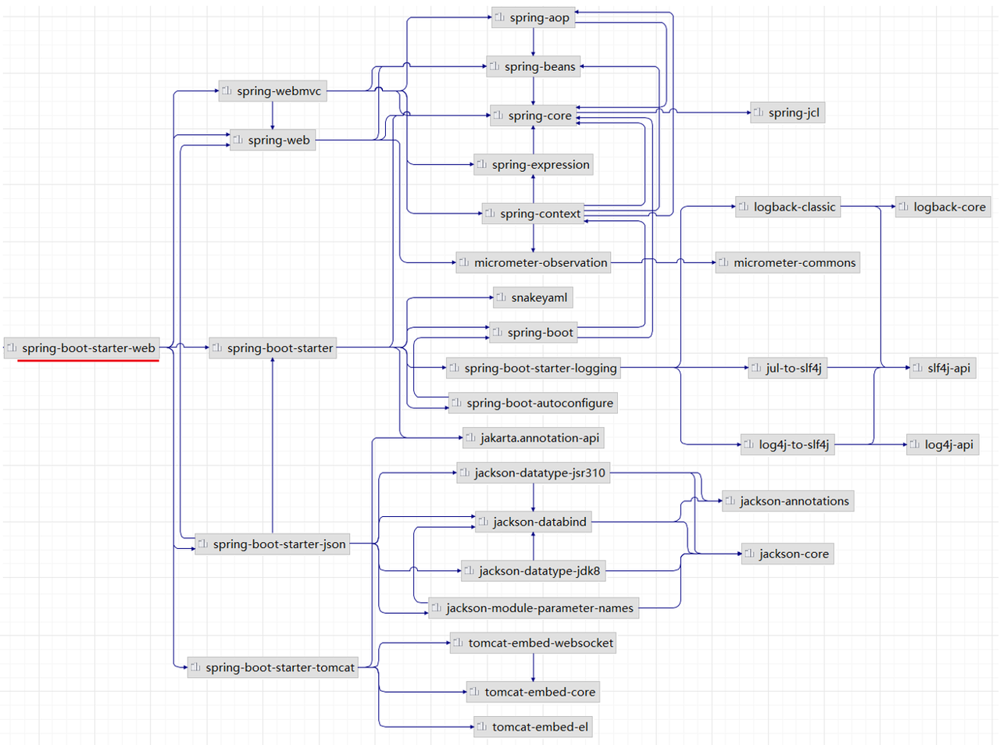

所以，起步依赖的原理就是Maven的依赖传递。

**讲义提示**

> - 在SpringBoot给我们提供的这些起步依赖当中，已提供了当前程序开发所需要的所有的常见依赖(官网地址：https://docs.spring.io/spring-boot/docs/2.7.7/reference/htmlsingle/#using.build-systems.starters)。

> - 比如：springboot-starter-web，这是web开发的起步依赖，在web开发的起步依赖当中，就集成了web开发中常见的依赖：json、web、webmvc、tomcat等。我们只需要引入这一个起步依赖，其他的依赖都会自动的通过Maven的依赖传递进来。

### 自动配置

> **补充｜条件装配。** 自动配置类一般使用 `@ConditionalOnClass`、`@ConditionalOnMissingBean`、`@ConditionalOnProperty` 等条件，只有运行环境满足条件时才注册 Bean。排查“为什么没生效”时，先确认依赖是否存在，再确认条件属性、包扫描和用户自定义 Bean。

SpringBoot的自动配置就是当spring容器启动后，一些配置类、bean对象就自动存入到了IOC容器中，不需要我们手动去声明，从而简化了开发，省去了繁琐的配置操作。

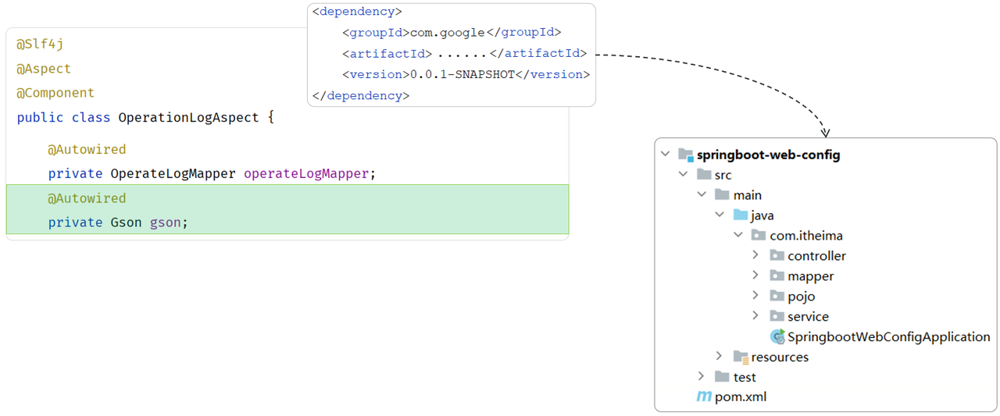

比如，在我们前面讲解AOP记录日志的那个案例中，我们要将一个对象转为json，直接注入一个Gson，然后就可以直接使用了。而我们在我们整个项目中，也并未配置Gson这个类型的bean，为什么可以直接注入使用呢？ 原因就是因为这个bean，springboot中已经帮我们自动配置完毕了，我们是可以直接使用的。

那接下来，我们就要来解析，SpringBoot中到底是如何完成自动配置的。

#### 实现方案

我们知道了什么是自动配置之后，接下来我们就要来剖析自动配置的原理。解析自动配置的原理就是分析在 SpringBoot项目当中，我们引入对应的依赖之后，是如何将依赖jar包当中所提供的bean以及配置类直接加载到当前项目的SpringIOC容器当中的。

接下来，我们就直接通过代码来分析自动配置原理。

- 准备工作：在Idea中导入"资料\03. 自动配置原理" 下的 itheima-utils 工程

- 在SpringBoot项目 spring-boot-web-config 工程中，通过坐标引入itheima-utils依赖

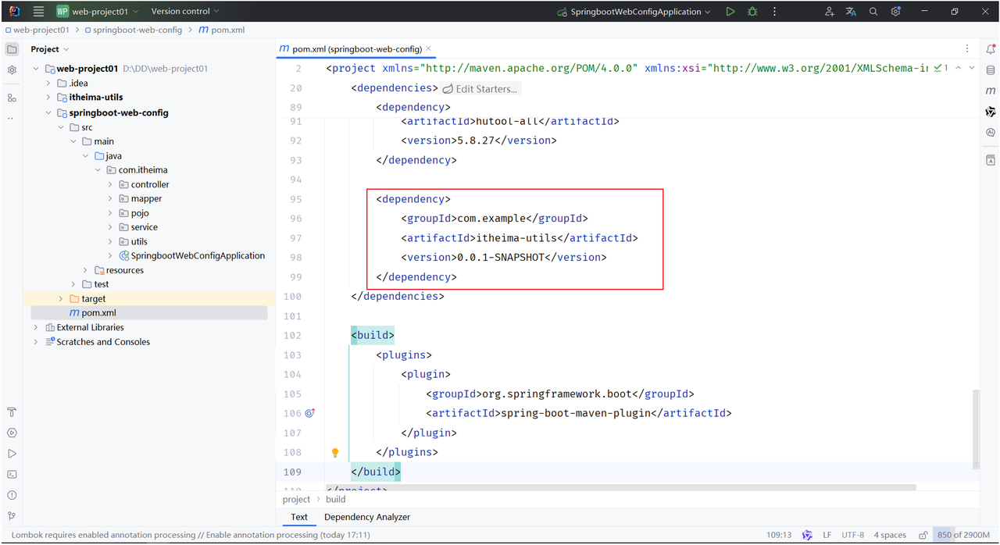

1、引入的 itheima-utils 中配置如下:

```java
@Component
public class TokenParser {
    public void parse(){
        System.out.println("TokenParser ... parse ...");
    }
}
```

2、在测试类中，添加测试方法

```java
@SpringBootTest
public class AutoConfigurationTests {
    @Autowired
    private ApplicationContext applicationContext;

    @Test
    public void testTokenParse(){
        System.out.println(applicationContext.getBean(TokenParser.class));
    }

    //省略其他代码...
}
```

3、执行测试方法

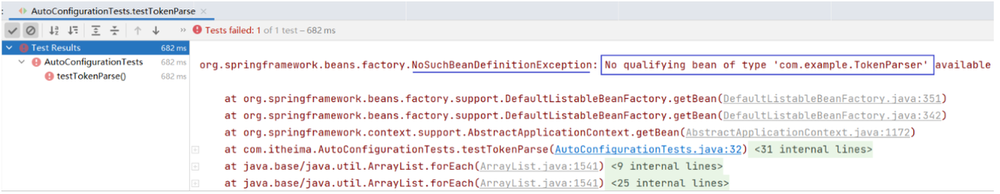

**讲义提示**

> 异常信息描述： 没有com.example.TokenParse类型的bean

> 说明：在Spring容器中没有找到com.example.TokenParse类型的bean对象

思考：引入进来的第三方依赖当中的bean以及配置类为什么没有生效？

- 原因在我们之前讲解IOC的时候有提到过，在类上添加@Component注解来声明bean对象时，还需要保证@Component注解能被Spring的组件扫描到。

- SpringBoot项目中的@SpringBootApplication注解，具有包扫描的作用，但是它只会扫描启动类所在的当前包以及子包。

- 当前包：com.itheima， 第三方依赖中提供的包：com.example（扫描不到）

那么如何解决以上问题的呢？

- 方案1：@ComponentScan 组件扫描

- 方案2：@Import 导入（使用@Import导入的类会被Spring加载到IOC容器中）

##### 方案一

@ComponentScan组件扫描

```java
@SpringBootApplication
@ComponentScan({"com.itheima","com.example"}) //指定要扫描的包
public class SpringbootWebConfigApplication {
    public static void main(String[] args) {
        SpringApplication.run(SpringbootWebConfigApplication.class, args);
    }
}
```

重新执行测试方法，控制台日志输出：

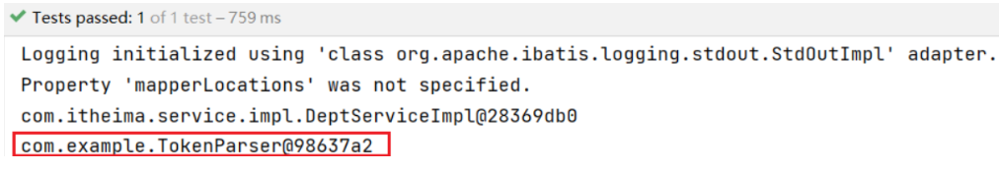

**讲义提示**

> 大家可以想象一下，如果采用以上这种方式来完成自动配置，那我们进行项目开发时，当需要引入大量的第三方的依赖，就需要在启动类上配置N多要扫描的包，这种方式会很繁琐。而且这种大面积的扫描性能也比较低。

> 缺点：

> 1. 使用繁琐

> 1. 性能低

> 结论：SpringBoot中并没有采用以上这种方案。

##### 方案二

@Import导入

- 导入形式主要有以下几种：

    1. 导入普通类

    1. 导入配置类

    1. 导入ImportSelector接口实现类

1). 使用@Import导入普通类：

```java
@Import(TokenParser.class) //导入的类会被Spring加载到IOC容器中
@SpringBootApplication
public class SpringbootWebConfigApplication {
    public static void main(String[] args) {
        SpringApplication.run(SpringbootWebConfigApplication.class, args);
    }
}
```

重新执行测试方法，控制台日志输出：

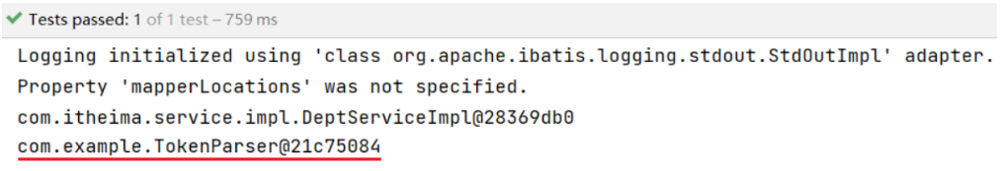

2). 使用@Import导入配置类：

- 配置类

```java
@Configuration
public class HeaderConfig {
    @Bean
    public HeaderParser headerParser(){
        return new HeaderParser();
    }

    @Bean
    public HeaderGenerator headerGenerator(){
        return new HeaderGenerator();
    }
}
```

- 启动类

```java
@Import(HeaderConfig.class) //导入配置类
@SpringBootApplication
public class SpringbootWebConfig2Application {
    public static void main(String[] args) {
        SpringApplication.run(SpringbootWebConfig2Application.class, args);
    }
}
```

- 测试类

```java
@SpringBootTest
public class AutoConfigurationTests {
    @Autowired
    private ApplicationContext applicationContext;

    @Test
    public void testHeaderParser(){
        System.out.println(applicationContext.getBean(HeaderParser.class));
    }

    @Test
    public void testHeaderGenerator(){
        System.out.println(applicationContext.getBean(HeaderGenerator.class));
    }
    
    //省略其他代码...
}
```

执行测试方法：

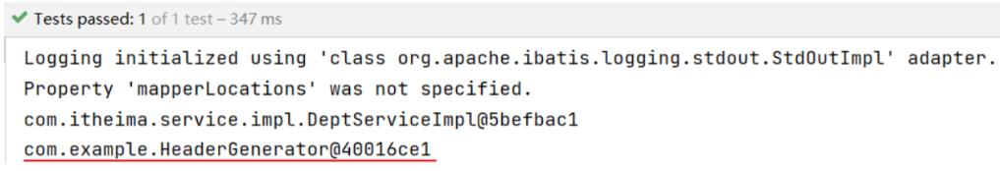

3). 使用@Import导入ImportSelector接口实现类：

- ImportSelector接口实现类

```java
public class MyImportSelector implements ImportSelector {
    public String[] selectImports(AnnotationMetadata importingClassMetadata) {
        //返回值字符串数组（数组中封装了全限定名称的类）
        return new String[]{"com.example.HeaderConfig"};
    }
}
```

- 启动类

```java
@Import(MyImportSelector.class) //导入ImportSelector接口实现类
@SpringBootApplication
public class SpringbootWebConfig2Application {
    public static void main(String[] args) {
        SpringApplication.run(SpringbootWebConfig2Application.class, args);
    }
}
```

执行测试方法：

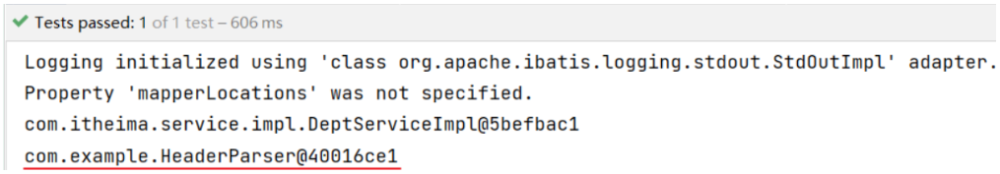

我们使用@Import注解通过这三种方式都可以导入第三方依赖中所提供的bean或者是配置类。

思考：如果基于以上方式完成自动配置，当要引入一个第三方依赖时，是不是还要知道第三方依赖中有哪些配置类和哪些Bean对象？

- 答案：是的。 （对程序员来讲，很不友好，而且比较繁琐）

思考：当我们要使用第三方依赖，依赖中到底有哪些bean和配置类，谁最清楚？

- 答案：第三方依赖自身最清楚。

**讲义提示**

> 结论：我们不用自己指定要导入哪些bean对象和配置类了，让第三方依赖它自己来指定。

怎么让第三方依赖自己指定bean对象和配置类？

- 比较常见的方案就是第三方依赖给我们提供一个注解，这个注解一般都以@EnableXxxx开头的注解，注解中封装的就是@Import注解

4). 使用第三方依赖提供的 @EnableXxxxx注解

- 第三方依赖中提供的注解

```java
@Retention(RetentionPolicy.RUNTIME)
@Target(ElementType.TYPE)
@Import(MyImportSelector.class)//指定要导入哪些bean对象或配置类
public @interface EnableHeaderConfig { 
}
```

- 在使用时只需在启动类上加上@EnableXxxxx注解即可

```java
@EnableHeaderConfig  //使用第三方依赖提供的Enable开头的注解
@SpringBootApplication
public class SpringbootWebConfig2Application {
    public static void main(String[] args) {
        SpringApplication.run(SpringbootWebConfig2Application.class, args);
    }
}
```

执行测试方法：

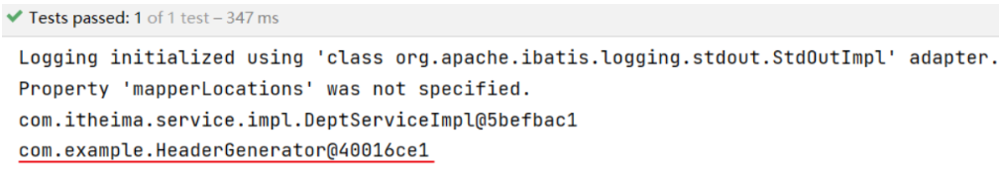

以上四种方式都可以完成导入操作，但是第4种方式会更方便更优雅，而这种方式也是SpringBoot当中所采用的方式。

#### 原理分析

##### 源码跟踪

前面我们讲解了在项目当中引入第三方依赖之后，如何加载第三方依赖中定义好的bean对象以及配置类，从而完成自动配置操作。那下面我们通过源码跟踪的形式来剖析下SpringBoot底层到底是如何完成自动配置的。

**讲义提示**

> 源码跟踪技巧：

> 在跟踪框架源码的时候，一定要抓住关键点，找到核心流程。一定不要从头到尾一行代码去看，一个方法的去研究，一定要找到关键流程，抓住关键点，先在宏观上对整个流程或者整个原理有一个认识，有精力再去研究其中的细节。

要搞清楚SpringBoot的自动配置原理，要从SpringBoot启动类上使用的核心注解@SpringBootApplication开始分析：

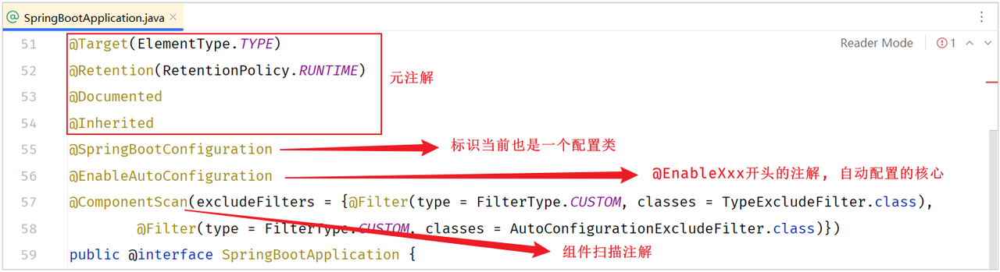

在@SpringBootApplication注解中包含了：

- 元注解（不再解释）

- @SpringBootConfiguration

- @EnableAutoConfiguration

- @ComponentScan

- 我们先来看第一个注解：@SpringBootConfiguration

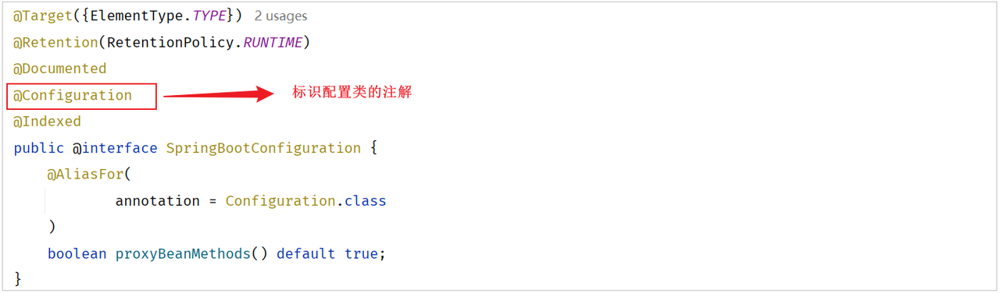

**讲义提示**

> @SpringBootConfiguration注解上使用了@Configuration，表明SpringBoot启动类就是一个配置类。

> @Indexed注解，是用来加速应用启动的（不用关心）。

- 接下来再先看@ComponentScan注解：

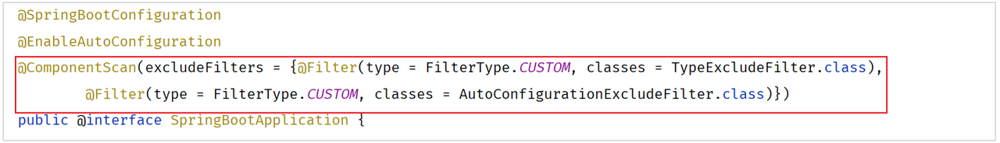

**讲义提示**

> @ComponentScan注解是用来进行组件扫描的，扫描启动类所在的包及其子包下所有被@Component及其衍生注解声明的类。

> SpringBoot启动类，之所以具备扫描包功能，就是因为包含了@ComponentScan注解。

- 最后我们来看看@EnableAutoConfiguration注解（自动配置核心注解）：

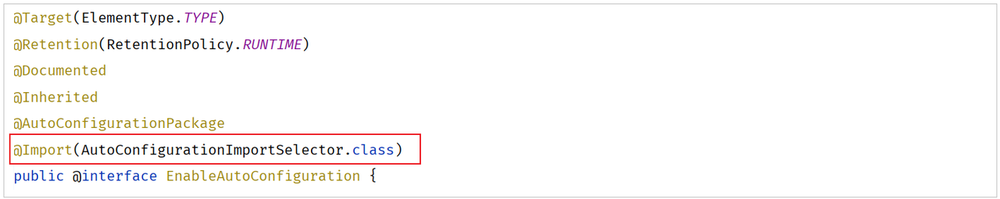

使用@Import注解，导入了实现ImportSelector接口的实现类。

AutoConfigurationImportSelector类是ImportSelector接口的实现类。

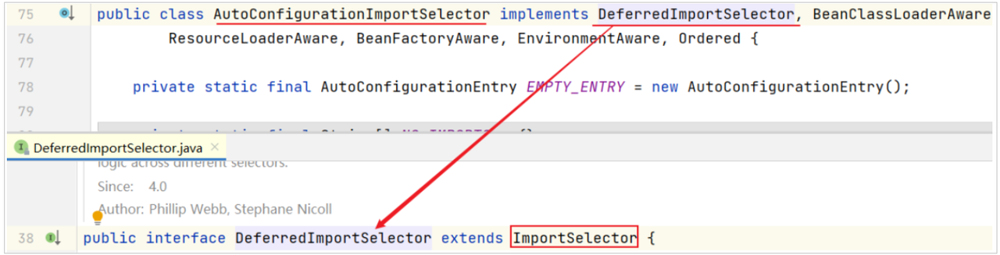

AutoConfigurationImportSelector类中重写了ImportSelector接口的selectImports()方法：

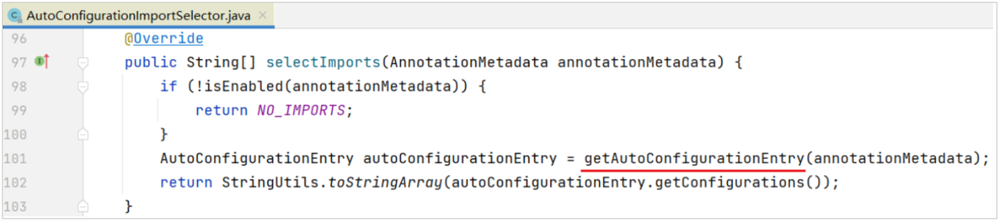

**讲义提示**

> selectImports()方法底层调用getAutoConfigurationEntry()方法，获取可自动配置的配置类信息集合

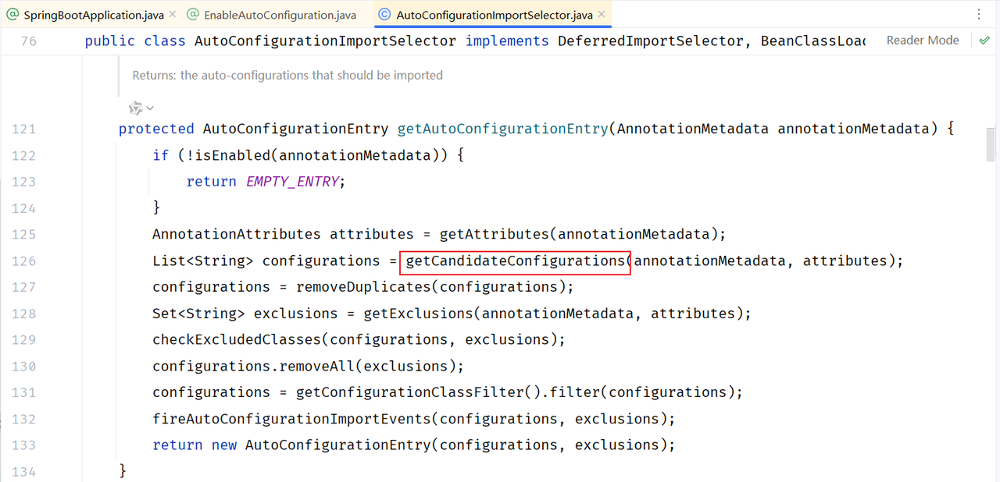

**讲义提示**

> getAutoConfigurationEntry()方法通过调用getCandidateConfigurations(annotationMetadata, attributes)方法获取在配置文件中配置的所有自动配置类的集合

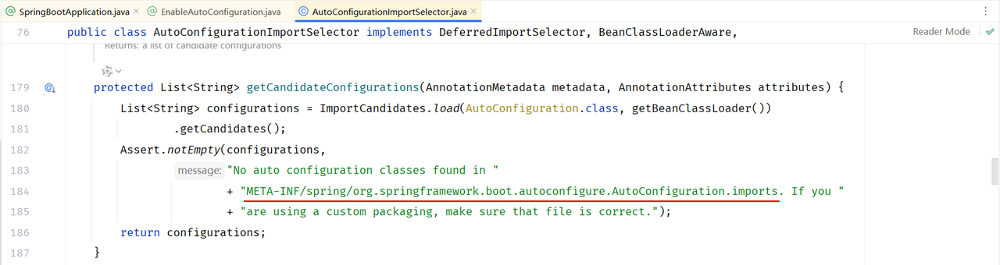

**讲义提示**

> getCandidateConfigurations方法的功能：

> 获取所有基于 META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports文件中配置类的集合

META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports文件这两个文件在哪里呢？

- 通常在引入的起步依赖中，都有包含以上文件

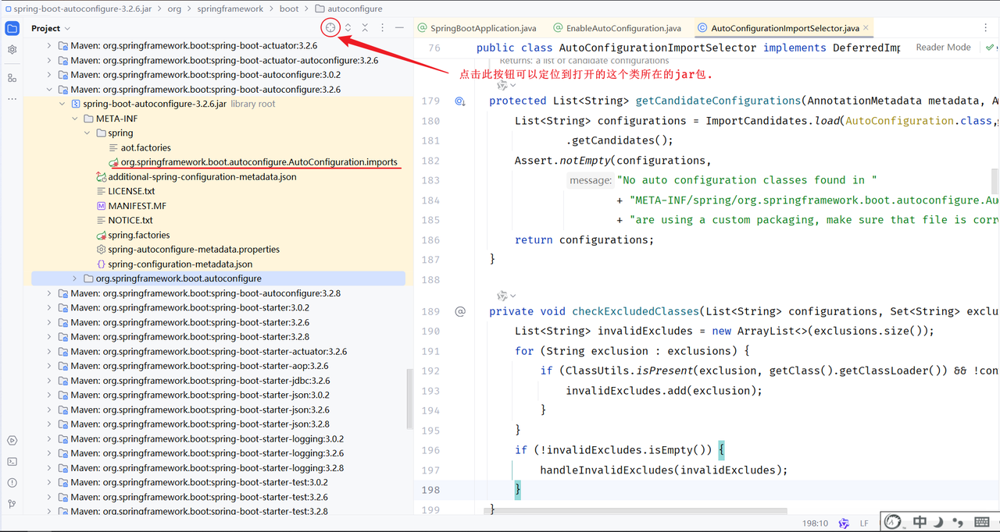

在前面在给大家演示自动配置的时候，我们直接在测试类当中注入了一个叫gson的bean对象，进行JSON格式转换。虽然我们没有配置bean对象，但是我们是可以直接注入使用的。原因就是因为在自动配置类当中做了自动配置。到底是在哪个自动配置类当中做的自动配置呢？我们通过搜索来查询一下。

在META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports 配置文件中指定了第三方依赖Gson的配置类：GsonAutoConfiguration

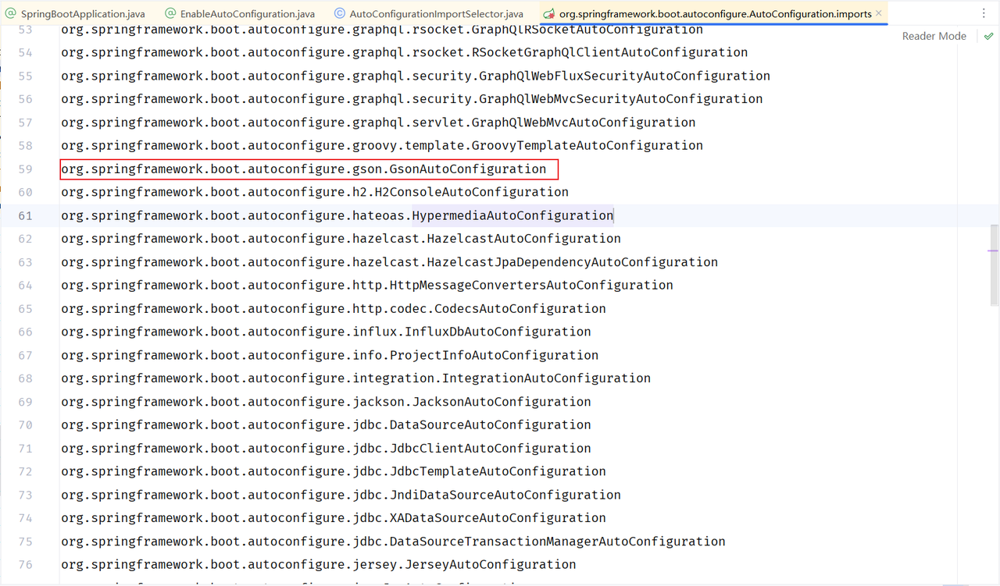

打开上面的第三方依赖中提供的 GsonAutoConfiguration 类：

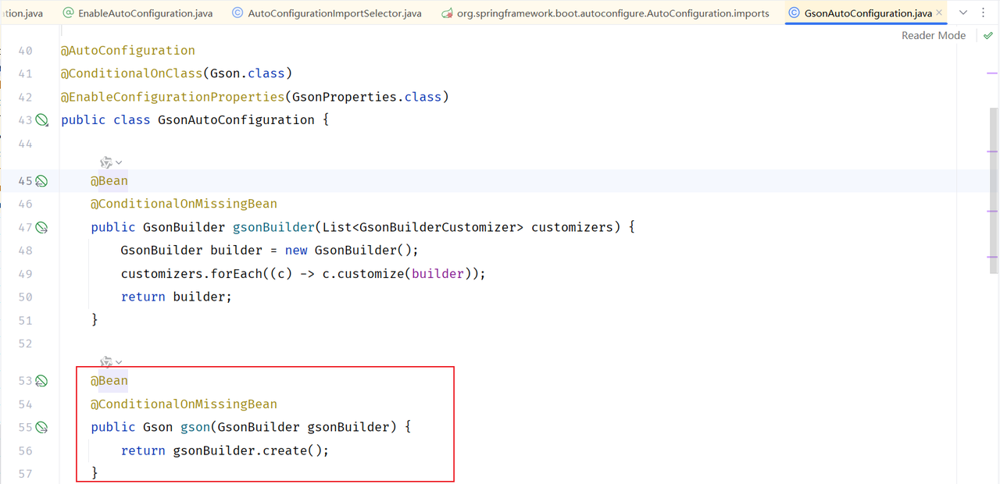

在GsonAutoConfiguration类上，添加了注解@AutoConfiguration，通过查看源码，可以明确：GsonAutoConfiguration 类是一个配置。

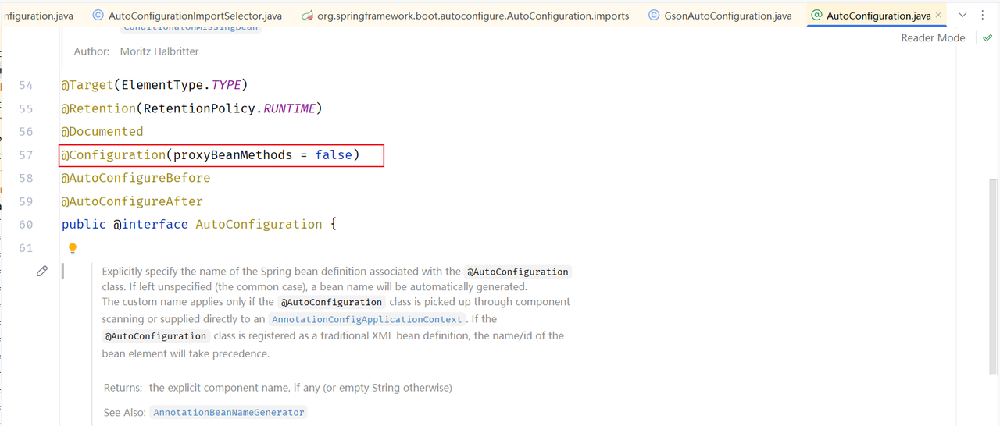

看到这里，大家就应该明白为什么可以完成自动配置了，原理就是在配置类中定义一个@Bean标识的方法，而Spring会自动调用配置类中使用@Bean标识的方法，并把方法的返回值注册到IOC容器中。

自动配置源码小结

自动配置原理源码入口就是 @SpringBootApplication 注解，在这个注解中封装了3个注解，分别是：

- @SpringBootConfiguration

    - 声明当前类是一个配置类

- @ComponentScan

    - 进行组件扫描（SpringBoot中默认扫描的是启动类所在的当前包及其子包）

- @EnableAutoConfiguration

    - 封装了@Import注解（Import注解中指定了一个ImportSelector接口的实现类）

在实现类重写的selectImports()方法，读取当前项目下所有依赖jar包中META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports两个文件里面定义的配置类（配置类中定义了@Bean注解标识的方法）。

当SpringBoot程序启动时，就会加载配置文件当中所定义的配置类，并将这些配置类信息(类的全限定名)封装到String类型的数组中，最终通过@Import注解将这些配置类全部加载到Spring的IOC容器中，交给IOC容器管理。

**讲义提示**

> 最后呢给大家抛出一个问题：在 META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports 文件中定义的配置类非常多，而且每个配置类中又可以定义很多的bean，那这些bean都会注册到Spring的IOC容器中吗？

> 答案：并不是。 在声明bean对象时，上面有加一个以 @Conditional 开头的注解，这种注解的作用就是按照条件进行装配，只有满足条件之后，才会将bean注册到Spring的IOC容器中（下面会详细来讲解）

##### @Conditional

我们在跟踪SpringBoot自动配置的源码的时候，在自动配置类声明bean的时候，除了在方法上加了一个@Bean注解以外，还会经常用到一个注解，就是以Conditional开头的这一类的注解。以Conditional开头的这些注解都是条件装配的注解。下面我们就来介绍下条件装配注解。

@Conditional注解：

- 作用：按照一定的条件进行判断，在满足给定条件后才会注册对应的bean对象到Spring的IOC容器中。

- 位置：方法、类

- @Conditional本身是一个父注解，派生出大量的子注解：

    - @ConditionalOnClass：判断环境中有对应字节码文件，才注册bean到IOC容器。

    - @ConditionalOnMissingBean：判断环境中没有对应的bean(类型或名称)，才注册bean到IOC容器。

    - @ConditionalOnProperty：判断配置文件中有对应属性和值，才注册bean到IOC容器。

下面我们通过代码来演示下Conditional注解的使用：

- @ConditionalOnClass注解

```java
@Configuration
public class HeaderConfig {

    @Bean
    @ConditionalOnClass(name="io.jsonwebtoken.Jwts")//环境中存在指定的这个类，才会将该bean加入IOC容器
    public HeaderParser headerParser(){
        return new HeaderParser();
    }
    
    //省略其他代码...
}
```

- pom.xml

```xml
<!--JWT令牌-->
<dependency>
     <groupId>io.jsonwebtoken</groupId>
     <artifactId>jjwt</artifactId>
     <version>0.9.1</version>
</dependency>
```

- 测试类

```java
@SpringBootTest
public class AutoConfigurationTests {
    @Autowired
    private ApplicationContext applicationContext;

    @Test
    public void testHeaderParser(){
        System.out.println(applicationContext.getBean(HeaderParser.class));
    }
    
    //省略其他代码...
}
```

执行testHeaderParser()测试方法：

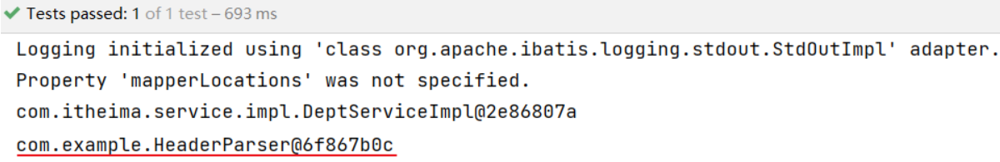

**讲义提示**

> 因为 io.jsonwebtoken.Jwts 字节码文件在启动SpringBoot程序时已存在，所以创建HeaderParser对象并注册到IOC容器中。

- @ConditionalOnMissingBean注解

```java
@Configuration
public class HeaderConfig {
        
    @Bean
    @ConditionalOnMissingBean //不存在该类型的bean，才会将该bean加入IOC容器
    public HeaderParser headerParser(){
        return new HeaderParser();
    }
    
    //省略其他代码...
}
```

执行testHeaderParser()测试方法：

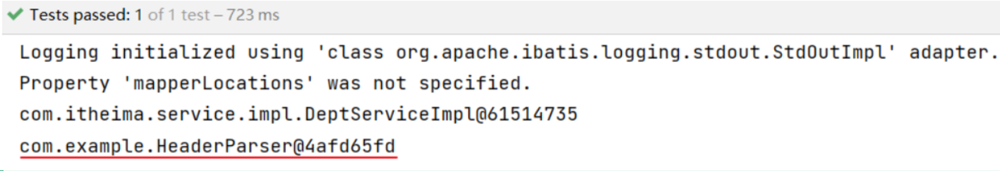

**讲义提示**

> SpringBoot在调用@Bean标识的headerParser()前，IOC容器中是没有HeaderParser类型的bean，所以HeaderParser对象正常创建，并注册到IOC容器中。

- 再次修改@ConditionalOnMissingBean注解

```java
@Configuration
public class HeaderConfig {

    @Bean
    @ConditionalOnMissingBean//不存在指定类型的bean，才会将该bean加入IOC容器
    public HeaderParser headerParser(){
        return new HeaderParser();
    }
    
    //省略其他代码...
}
```

执行testHeaderParser()测试方法：

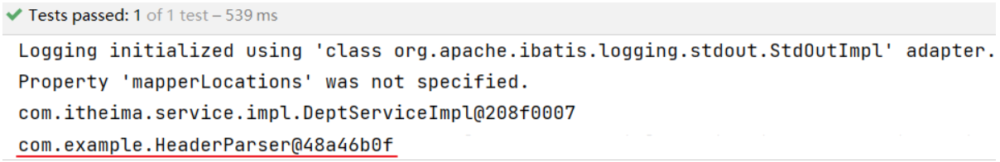

- @ConditionalOnProperty注解（这个注解和配置文件当中配置的属性有关系）

先在application.yml配置文件中添加如下的键值对：

```yaml
name: itheima
```

在声明bean的时候就可以指定一个条件@ConditionalOnProperty

```java
@Configuration
public class HeaderConfig {

    @Bean
    @ConditionalOnProperty(name ="name",havingValue = "itheima")//配置文件中存在指定属性名与值，才会将bean加入IOC容器
    public HeaderParser headerParser(){
        return new HeaderParser();
    }

    @Bean
    public HeaderGenerator headerGenerator(){
        return new HeaderGenerator();
    }
}
```

执行testHeaderParser()测试方法：

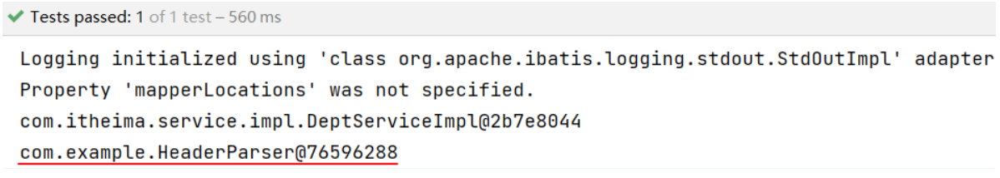

修改@ConditionalOnProperty注解：  havingValue的值修改为"itheima2"

```java
@Bean
@ConditionalOnProperty(name ="name",havingValue = "itheima2")//配置文件中存在指定属性名与值，才会将bean加入IOC容器
public HeaderParser headerParser(){
        return new HeaderParser();
}
```

再次执行testHeaderParser()测试方法：

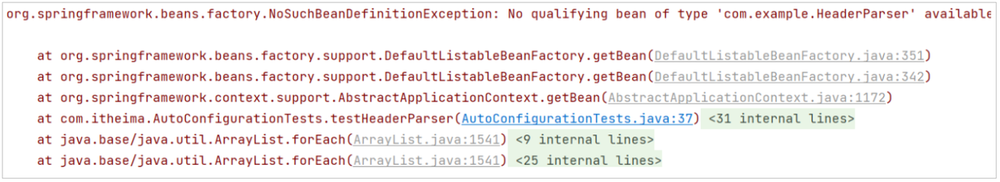

**讲义提示**

> 因为 application.yml 配置文件中，不存在： name:  itheima2，所以HeaderParser对象在IOC容器中不存在

我们再回头看看之前讲解SpringBoot源码时提到的一个配置类：GsonAutoConfiguration

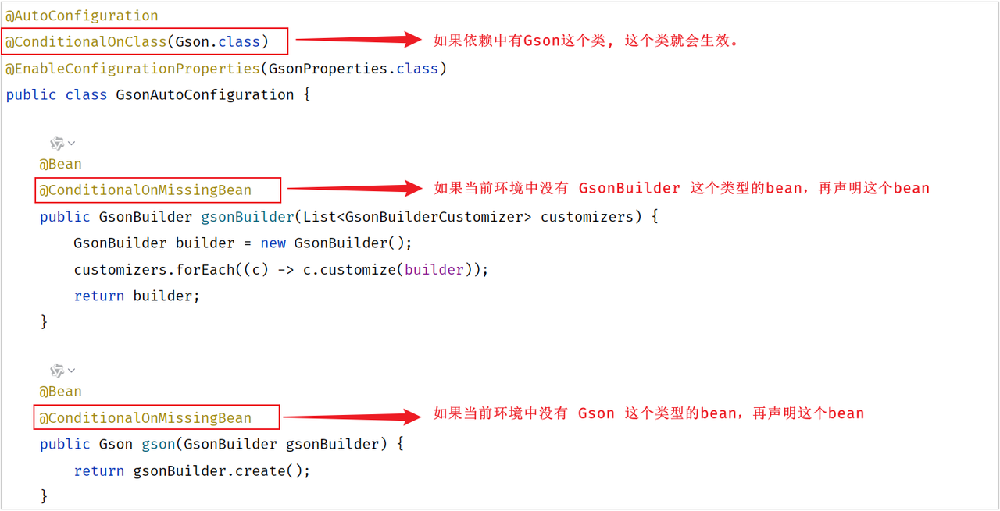

最后再给大家梳理一下自动配置原理：

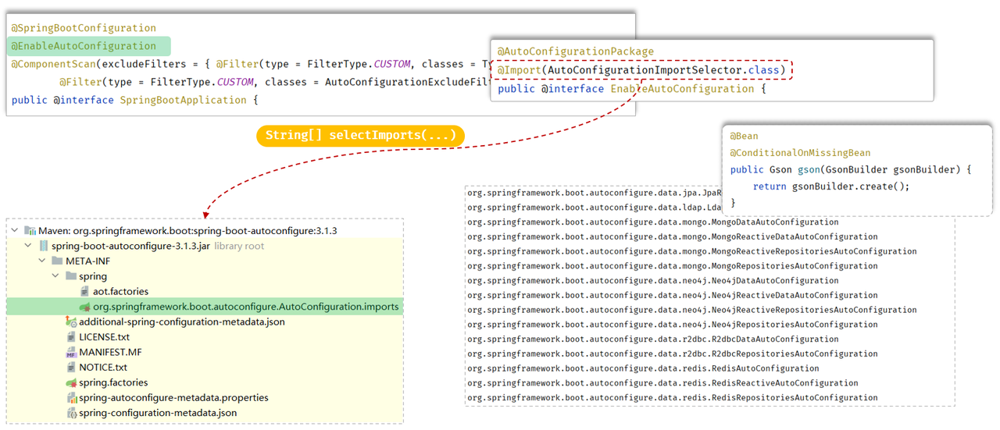

**讲义提示**

> 自动配置的核心就在@SpringBootApplication注解上，SpringBootApplication这个注解底层包含了3个注解，分别是：

> - @SpringBootConfiguration

> - @ComponentScan

> - @EnableAutoConfiguration

> @EnableAutoConfiguration这个注解才是自动配置的核心。

> - 它封装了一个@Import注解，Import注解里面指定了一个ImportSelector接口的实现类。

> - 在这个实现类中，重写了ImportSelector接口中的selectImports()方法。

> - 而selectImports()方法中会去读取两份配置文件，并将配置文件中定义的配置类做为selectImports()方法的返回值返回，返回值代表的就是需要将哪些类交给Spring的IOC容器进行管理。

> - 那么所有自动配置类的中声明的bean都会加载到Spring的IOC容器中吗? 其实并不会，因为这些配置类中在声明bean时，通常都会添加@Conditional开头的注解，这个注解就是进行条件装配。而Spring会根据Conditional注解有选择性的进行bean的创建。

> - @Enable 开头的注解底层，它就封装了一个注解 import 注解，它里面指定了一个类，是 ImportSelector 接口的实现类。在实现类当中，我们需要去实现 ImportSelector  接口当中的一个方法 selectImports 这个方法。这个方法的返回值代表的就是我需要将哪些类交给 spring 的 IOC容器进行管理。

> - 此时它会去读取两份配置文件，一份儿是 spring.factories，另外一份儿是 autoConfiguration.imports。而在  autoConfiguration.imports 这份儿文件当中，它就会去配置大量的自动配置的类。

> - 而前面我们也提到过这些所有的自动配置类当中，所有的 bean都会加载到 spring 的 IOC 容器当中吗？其实并不会，因为这些配置类当中，在声明 bean 的时候，通常会加上这么一类@Conditional 开头的注解。这个注解就是进行条件装配。所以SpringBoot非常的智能，它会根据 @Conditional 注解来进行条件装配。只有条件成立，它才会声明这个bean，才会将这个 bean 交给 IOC 容器管理。

#### 自定义starter

> **补充｜starter 设计建议。** 将自动配置实现放在独立模块，starter 只聚合依赖；使用 `@ConfigurationProperties` 承载可配置项，并给属性加前缀。默认行为应安全、可关闭，避免在类路径出现某个库时无条件创建线程池或连接。

##### 分析

前面我们解析了SpringBoot中自动配置的原理，下面我们就通过一个自定义starter案例来加深大家对于自动配置原理的理解。首先介绍一下自定义starter的业务场景，再来分析一下具体的操作步骤。

所谓starter指的就是SpringBoot当中的起步依赖。在SpringBoot当中已经给我们提供了很多的起步依赖了，我们为什么还需要自定义 starter 起步依赖？

这是因为在实际的项目开发当中，我们可能会用到很多第三方的技术，并不是所有的第三方的技术官方都给我们提供了与SpringBoot整合的starter起步依赖，但是这些技术又非常的通用，在很多项目组当中都在使用。

业务场景：

- 我们前面案例当中所使用的阿里云OSS对象存储服务，现在阿里云的官方是没有给我们提供对应的起步依赖的，这个时候使用起来就会比较繁琐，我们需要引入对应的依赖。我们还需要在配置文件当中进行配置，还需要基于官方SDK示例来改造对应的工具类，我们在项目当中才可以进行使用。

- 大家想在我们当前项目当中使用了阿里云OSS，我们需要进行这么多步的操作。在别的项目组当中要想使用阿里云OSS，是不是也需要进行这么多步的操作，所以这个时候我们就可以自定义一些公共组件，在这些公共组件当中，我就可以提前把需要配置的bean都提前配置好。将来在项目当中，我要想使用这个技术，我直接将组件对应的坐标直接引入进来，就已经自动配置好了，就可以直接使用了。我们也可以把公共组件提供给别的项目组进行使用，这样就可以大大的简化我们的开发。

在SpringBoot项目中，一般都会将这些公共组件封装为SpringBoot当中的starter，也就是我们所说的起步依赖。

而在springboot中，官方提供的起步依赖 或 第三方提供的起步依赖，基本都会包含两个模块，如下所示：

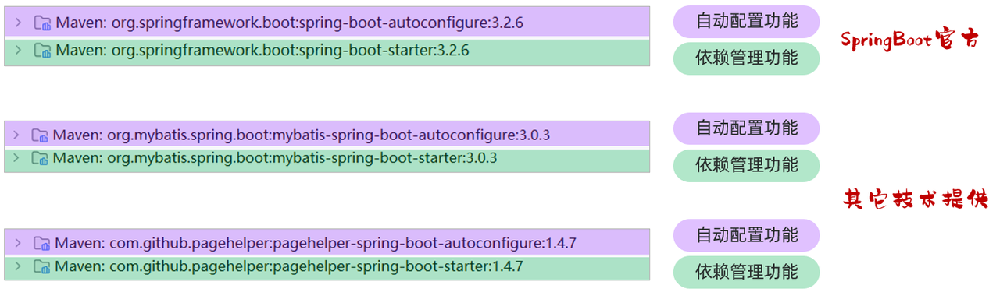

其中，spring-boot-starter  或  xxx-spring-boot-starter 这个模块主要是依赖管理的功能。 而 spring-boot-autoconfigure 或 xxxx-spring-boot-autoconfigure 主要是起到自动配置的作用，自动配置的核心代码就在这个模块中编写。

**讲义提示**

> SpringBoot官方starter命名： spring-boot-starter-xxxx

> 第三组织提供的starter命名：  xxxx-spring-boot-starter

而自动配置模块的核心，就是编写自动配置的核心代码，然后将自动配置的核心类，配置在核心的配置文件 META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports 中。 配置如下：

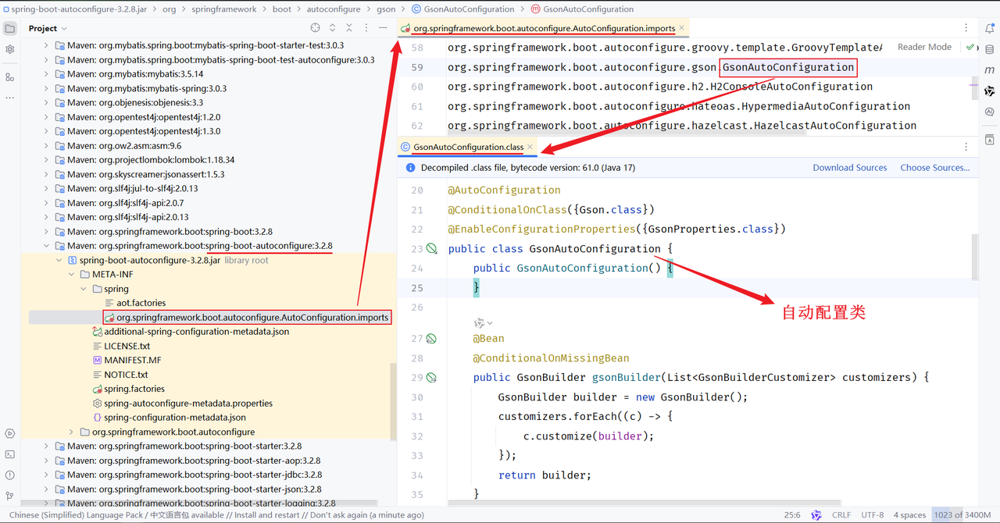

**讲义提示**

> SpringBoot官方的自动配置依赖 spring-boot-autoconfiure 中就提供了配置类，并且也提供了springboot会自动读取的配置文件。当SpringBoot项目启动时，会读取到META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports配置文件中的配置类并加载配置类，生成相关bean对象注册到IOC容器中。

> 结果：我们可以直接在SpringBoot程序中使用自动配置的bean对象。

在自定义一个起步依赖starter的时候，按照规范需要定义两个模块：

1. starter模块（进行依赖管理[把程序开发所需要的依赖都定义在starter起步依赖中]）

1. autoconfigure模块（自动配置）

**讲义提示**

> 将来在项目当中进行相关功能开发时，只需要引入一个起步依赖就可以了，因为它会将autoconfigure自动配置的依赖给传递下来。

##### 需求

上面我们简单介绍了自定义starter的场景，以及自定义starter时涉及到的模块之后，接下来我们就来完成一个自定义starter的案例。

- 需求：自定义aliyun-oss-spring-boot-starter，完成阿里云OSS操作工具类 AliyunOSSOperator 的自动配置。

- 目标：引入起步依赖引入之后，要想使用阿里云OSS，注入AliyunOSSOperator 直接使用即可。

之前我们的用法：

1). 在pom.xml中引入阿里云oss的所有依赖

```xml
<!--阿里云OSS-->
<dependency>
    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-sdk-oss</artifactId>
    <version>3.17.4</version>
</dependency>
<dependency>
    <groupId>javax.xml.bind</groupId>
    <artifactId>jaxb-api</artifactId>
    <version>2.3.1</version>
</dependency>
<dependency>
    <groupId>javax.activation</groupId>
    <artifactId>activation</artifactId>
    <version>1.1.1</version>
</dependency>
<!-- no more than 2.3.3-->
<dependency>
    <groupId>org.glassfish.jaxb</groupId>
    <artifactId>jaxb-runtime</artifactId>
    <version>2.3.3</version>
</dependency>
```

2). application.yml 中配置阿里云OSS的配置信息

```yaml
#阿里云oss配置
aliyun:
  oss:
    endpoint: https://oss-cn-beijing.aliyuncs.com
    bucketName: java422-web-ai
```

3). 定义实体类封装配置信息

```java
package com.itheima.utils;

import lombok.Data;
import org.springframework.boot.context.properties.ConfigurationProperties;
import org.springframework.stereotype.Component;

@Data
@Component
@ConfigurationProperties(prefix = "aliyun.oss")
public class AliyunOSSProperties {
    private String endpoint;
    private String bucketName;
}
```

4). 定义工具类AliyunOSSOperator

```java
package com.itheima.utils;

import com.aliyun.oss.OSS;
import com.aliyun.oss.OSSClientBuilder;
import com.aliyun.oss.common.auth.CredentialsProviderFactory;
import com.aliyun.oss.common.auth.EnvironmentVariableCredentialsProvider;
import com.aliyun.oss.model.OSSObjectSummary;
import com.aliyun.oss.model.ObjectListing;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Component;

import java.io.ByteArrayInputStream;
import java.time.LocalDate;
import java.time.format.DateTimeFormatter;
import java.util.List;
import java.util.UUID;
import java.util.stream.Collectors;

@Component
public class AliyunOSSOperator {

    @Autowired
    private AliyunOSSProperties aliyunOSSProperties;

    /**
     * 文件上传
     */
    public String upload(byte[] content, String originalFilename) throws Exception {
        String endpoint = aliyunOSSProperties.getEndpoint();
        String bucketName = aliyunOSSProperties.getBucketName();

        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();

        // 填写Object完整路径，例如202406/1.png。Object完整路径中不能包含Bucket名称。
        //获取当前系统日期的字符串,格式为 yyyy/MM
        String dir = LocalDate.now().format(DateTimeFormatter.ofPattern("yyyy/MM"));
        //根据原始文件名originalFilename, 生成一个新的不重复的文件名
        String newFileName = UUID.randomUUID().toString() + originalFilename.substring(originalFilename.lastIndexOf("."));
        String objectName = dir + "/" + newFileName;

        // 创建OSSClient实例。
        OSS ossClient = new OSSClientBuilder().build(endpoint, credentialsProvider);

        //文件上传
        try {
            ossClient.putObject(bucketName, objectName, new ByteArrayInputStream(content));
        } finally {
            if (ossClient != null) {
                ossClient.shutdown();
            }
        }

        return endpoint.split("//")[0] + "//" + bucketName + "." + endpoint.split("//")[1] + "/" + objectName;
    }


    /**
     * 查询文件列表
     */
    public List<String> listFiles() throws Exception {
        String endpoint = aliyunOSSProperties.getEndpoint();
        String bucketName = aliyunOSSProperties.getBucketName();
        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();
        // 指定前缀，例如exampledir/object。
        String keyPrefix = null;

        // 创建OSSClient实例。
        OSS ossClient = new OSSClientBuilder().build(endpoint, credentialsProvider);

        try {
            // 列举文件。如果不设置keyPrefix，则列举存储空间下的所有文件。如果设置keyPrefix，则列举包含指定前缀的文件。
            ObjectListing objectListing = ossClient.listObjects(bucketName, keyPrefix);
            List<OSSObjectSummary> sums = objectListing.getObjectSummaries();
            if(sums != null && !sums.isEmpty()){
                return sums.stream().map(OSSObjectSummary::getKey).collect(Collectors.toList());
            }
        } finally {
            if (ossClient != null) {
                ossClient.shutdown();
            }
        }
        return null;
    }

    /**
     * 删除指定对象
     */
    public void deleteFile(String objectName) throws Exception {
        String endpoint = aliyunOSSProperties.getEndpoint();
        String bucketName = aliyunOSSProperties.getBucketName();

        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();
        // 创建OSSClient实例。
        OSS ossClient = new OSSClientBuilder().build(endpoint, credentialsProvider);

        try {
            // 删除文件或目录。如果要删除目录，目录必须为空。
            ossClient.deleteObject(bucketName, objectName);
        } finally {
            if (ossClient != null) {
                ossClient.shutdown();
            }
        }
    }

}
```

5). 其他地方要使用阿里云OSS，注入工具类，再使用

```java
@Slf4j
@RestController
public class UploadController {
    @Autowired
    private AliyunOSSOperator aliyunOSSOperator;

    /**
     * 文件上传
     */
    @PostMapping("/upload")
    public Result upload(MultipartFile file) throws Exception {
        log.info("上传文件：{}",file.getOriginalFilename());
        //调用aliyun OSS进行文件上传
        String url = aliyunOSSOperator.upload(file.getBytes(), file.getOriginalFilename());
        //返回结果
        return Result.success(url);
    }
}
```

我们可以看到，在项目中使用阿里云OSS，需要这么五步操作，而阿里云OSS这个云服务还是非常常见的，很多项目中都要使用。

大家再思考，现在我们使用阿里云OSS，需要做这么几步，将来大家在开发其他的项目的时候，你使用阿里云OSS，这几步你要不要做？当团队中其他小伙伴也在使用阿里云OSS的时候，步骤 不也是一样的。

所以这个时候我们就可以制作一个公共组件(自定义starter)。starter定义好之后，将来要使用阿里云OSS进行文件上传，只需要将起步依赖引入进来之后，就可以直接注入 AliyunOSSOperator 使用了。

##### 实现

需求明确了，接下来我们再来分析一下具体的实现步骤：

- 第1步：创建自定义starter模块 aliyun-oss-spring-boot-starter（进行依赖管理）

    - 把阿里云OSS所有的依赖统一管理起来

- 第2步：创建autoconfigure模块 aliyun-oss-spring-boot-autoconfigure

    - 在starter中引入autoconfigure （我们使用时只需要引入starter起步依赖即可）

- 第3步：在autoconfigure模块aliyun-oss-spring-boot-autoconfigure中完成自动配置

    1. 定义一个自动配置类，在自动配置类中将所要配置的bean都提前配置好

    1. 定义配置文件，把自动配置类的全类名定义在配置文件(META-INF/spring/xxxx.imports)中

我们分析完自定义阿里云OSS自动配置的操作步骤了，下面我们就按照分析的步骤来实现自定义starter。

首先我们先来创建两个Maven模块：

1). 创建 aliyun-oss-spring-boot-starter

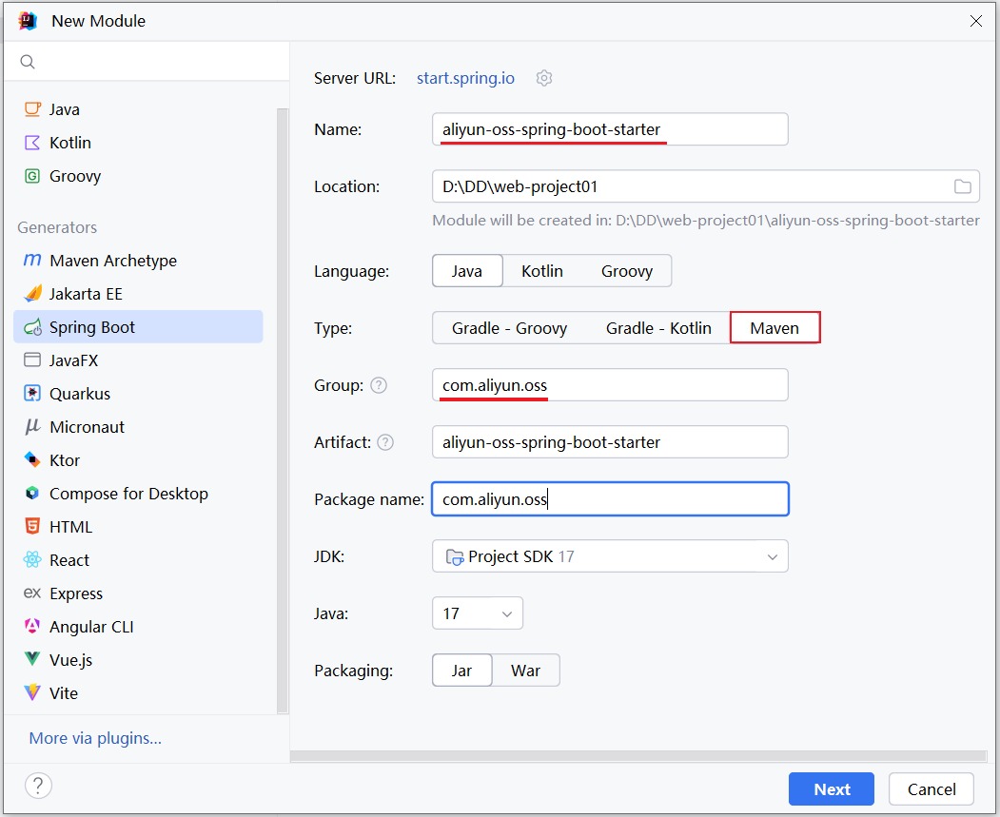

选择springboot的版本，不需要勾选任何的依赖。直接点击 create 创建项目。

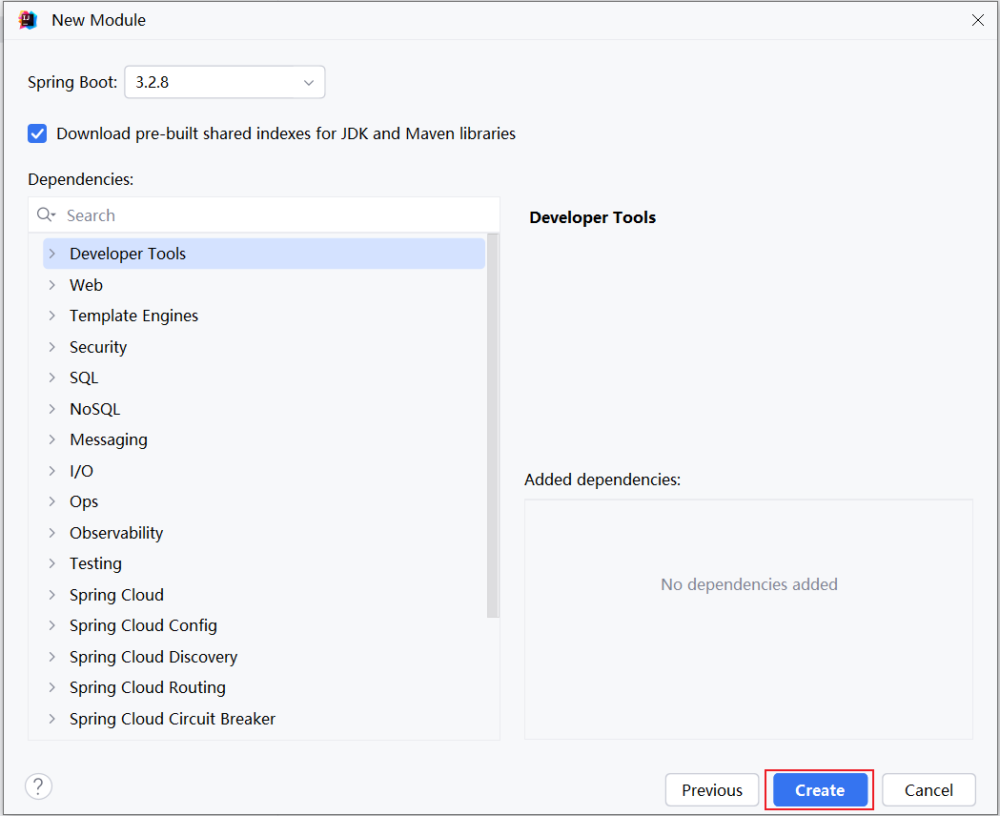

创建完starter模块后，删除多余的文件，只保留一个pom.xml文件。最终保留内容如下：

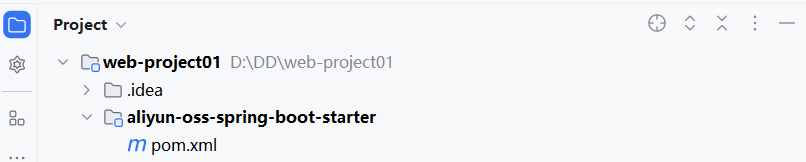

pom.xml 中的配置如下:

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-oss-spring-boot-starter</artifactId>
    <version>0.0.1-SNAPSHOT</version>

    <properties>
        <java.version>17</java.version>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter</artifactId>
        </dependency>
    </dependencies>

</project>
```

2). 创建 aliyun-oss-spring-boot-autoconfigure 模块

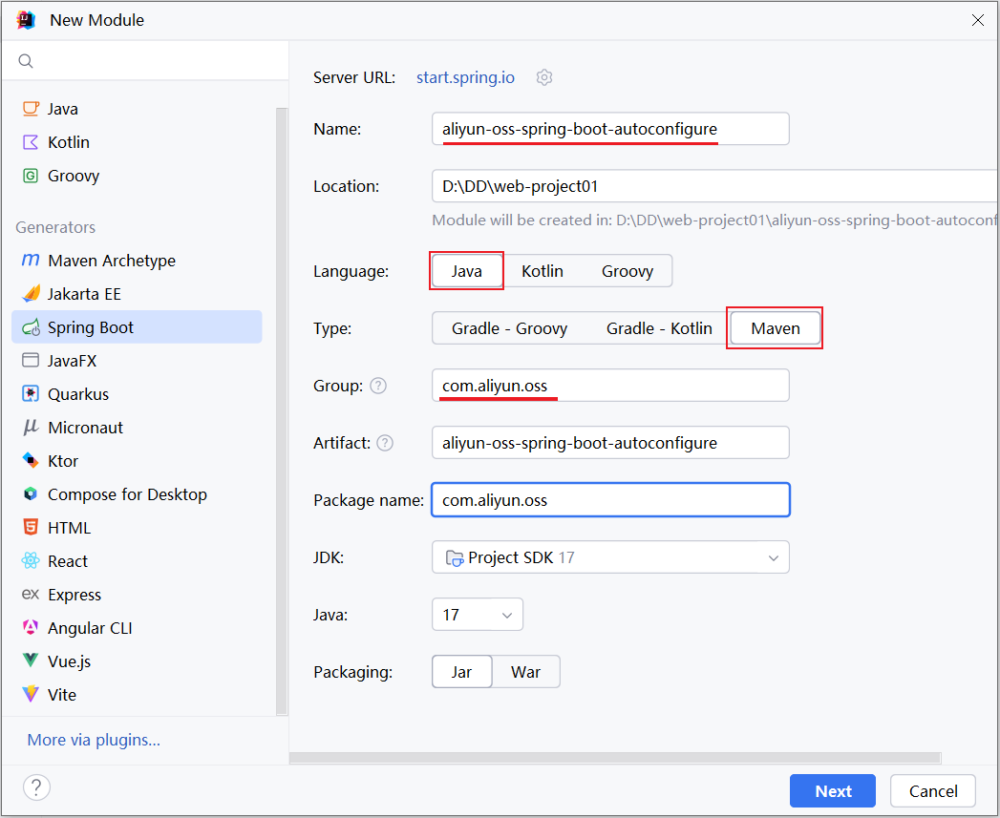

选择Springboot的版本，不用勾选任何依赖。

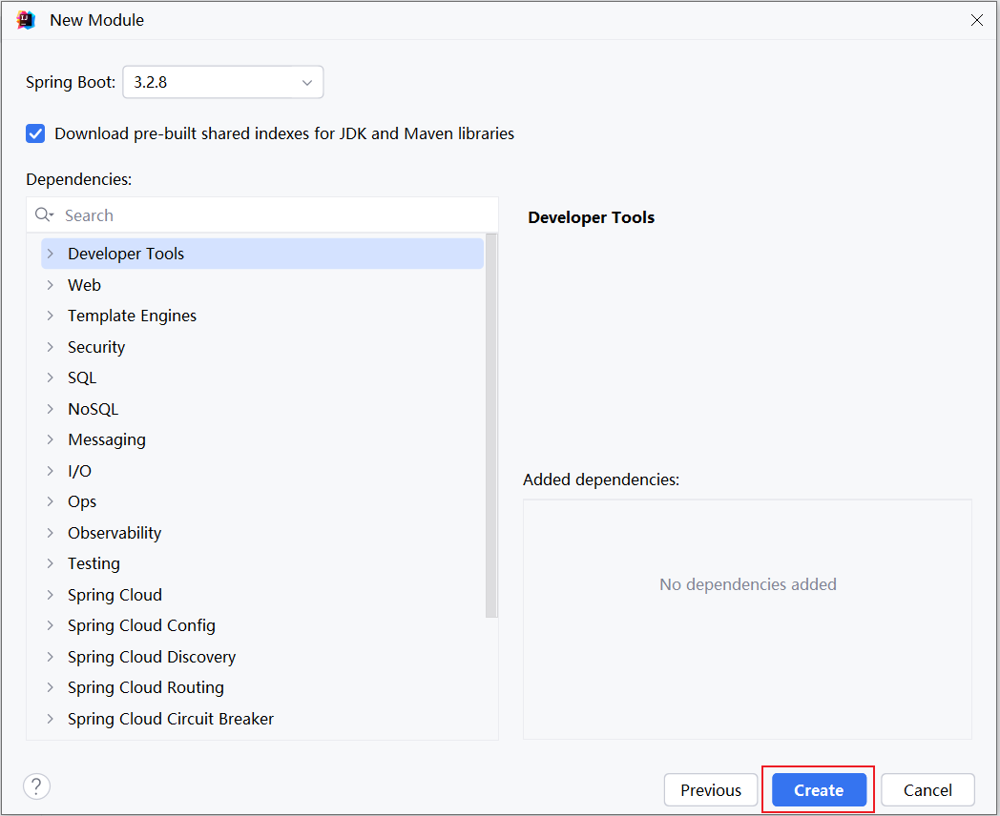

创建完starter模块后，删除多余的文件，只保留 src 和 pom.xml 。最终保留内容如下：

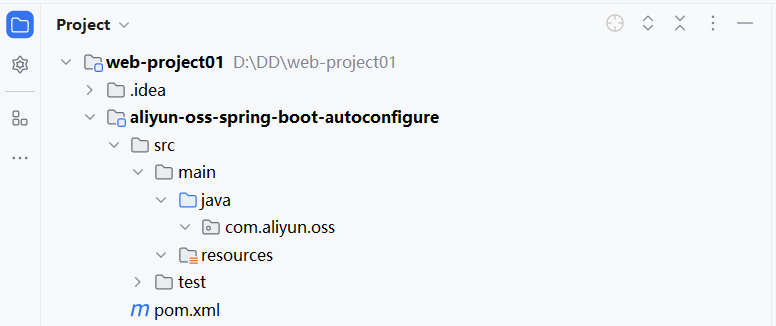

该模块的pom.xml内容如下：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-oss-spring-boot-autoconfigure</artifactId>
    <version>0.0.1-SNAPSHOT</version>

    <properties>
        <java.version>17</java.version>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter</artifactId>
        </dependency>
    </dependencies>

</project>
```

按照我们之前的分析，是需要在starter模块中来引入autoconfigure这个模块的。打开starter模块中的pom文件：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-oss-spring-boot-starter</artifactId>
    <version>0.0.1-SNAPSHOT</version>

    <properties>
        <java.version>17</java.version>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter</artifactId>
        </dependency>

        <dependency>
            <groupId>com.aliyun.oss</groupId>
            <artifactId>aliyun-oss-spring-boot-autoconfigure</artifactId>
            <version>0.0.1-SNAPSHOT</version>
        </dependency>
    </dependencies>

</project>
```

前两步已经完成了，接下来是最关键的就是第三步：在aliyun-oss-spring-boot-autoconfigure模块当中来完成自动配置操作。

**讲义提示**

> 我们将之前案例中所使用的阿里云OSS部分的代码直接拷贝到autoconfigure模块下，然后进行改造就行了。

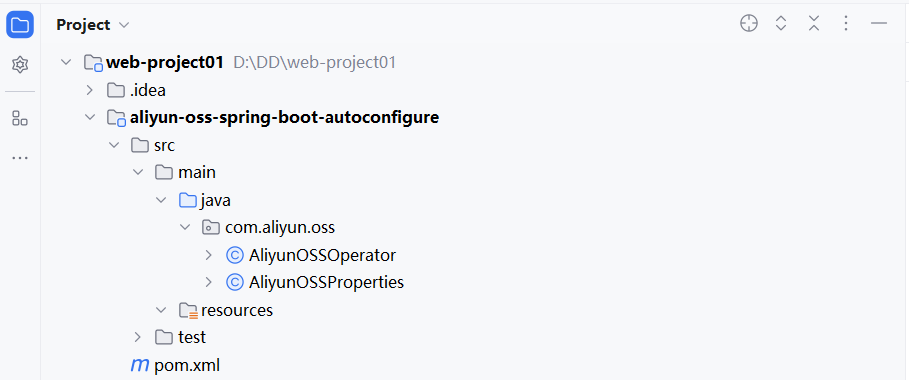

拷贝过来后，还缺失一些相关的依赖，需要把相关依赖也拷贝过来：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-oss-spring-boot-autoconfigure</artifactId>
    <version>0.0.1-SNAPSHOT</version>

    <properties>
        <java.version>17</java.version>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter</artifactId>
        </dependency>

        <dependency>
            <groupId>org.projectlombok</groupId>
            <artifactId>lombok</artifactId>
        </dependency>

        <!--阿里云OSS-->
        <dependency>
            <groupId>com.aliyun.oss</groupId>
            <artifactId>aliyun-sdk-oss</artifactId>
            <version>3.17.4</version>
        </dependency>
        <dependency>
            <groupId>javax.xml.bind</groupId>
            <artifactId>jaxb-api</artifactId>
            <version>2.3.1</version>
        </dependency>
        <dependency>
            <groupId>javax.activation</groupId>
            <artifactId>activation</artifactId>
            <version>1.1.1</version>
        </dependency>
        <!-- no more than 2.3.3-->
        <dependency>
            <groupId>org.glassfish.jaxb</groupId>
            <artifactId>jaxb-runtime</artifactId>
            <version>2.3.3</version>
        </dependency>

    </dependencies>

</project>
```

那此时，大家思考下，在类上添加的 @Component 注解还有用吗？

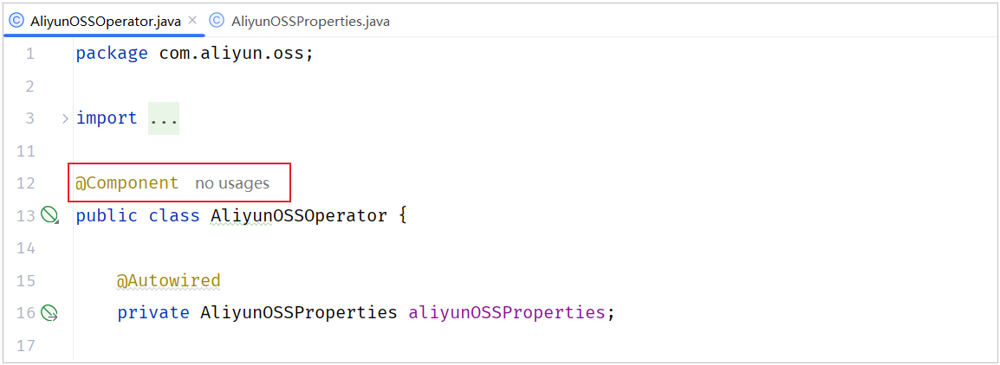

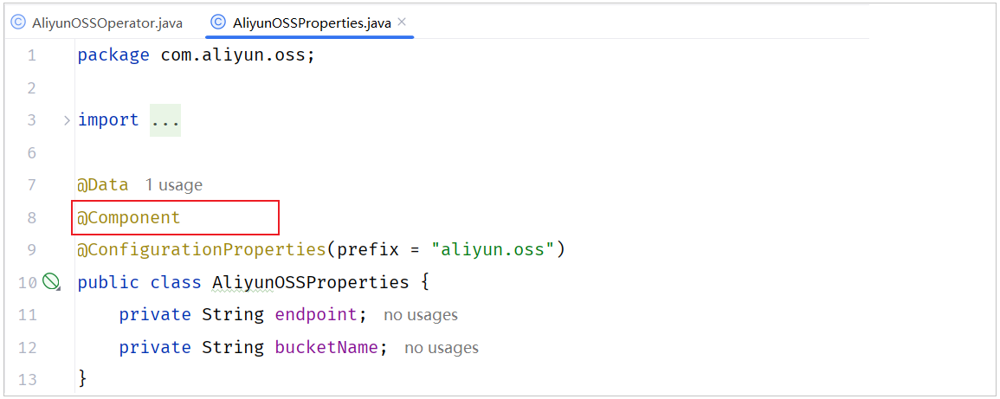

答案：没用了。  在SpringBoot项目中，并不会去扫描com.aliyun.oss这个包，不扫描这个包那类上的注解也就失去了作用。

@Component注解不需要使用了，可以从类上删除了。

1). 删除 AliyunOSSOperator 工具类上的 @Component 注解 和 @Autowired 注解。

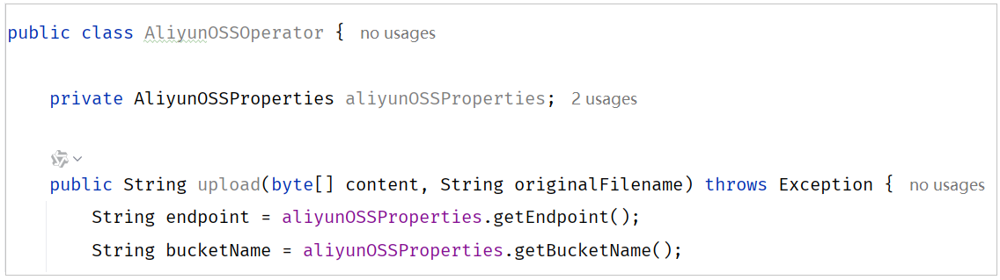

2). 删除 AliyunOSSProperties 实体类上的 @Component 注解。

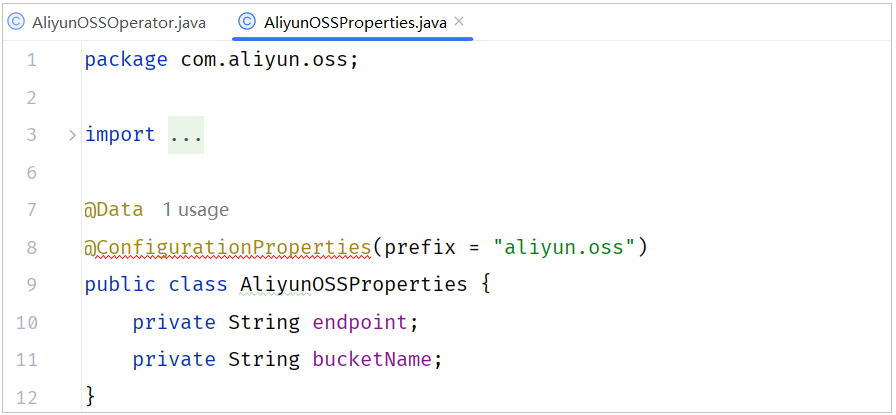

删除后报红色错误，暂时不理会，后面再来处理。

3). 既然不能用 @Component 注解声明bean，那就需要按照 starter 的定义规范，定义一个自动配置类，在自动配置类中声明bean。

下面我们就要定义一个自动配置类 AliOSSAutoConfiguration 了，在自动配置类当中来声明 AliOSSOperator 的bean对象。

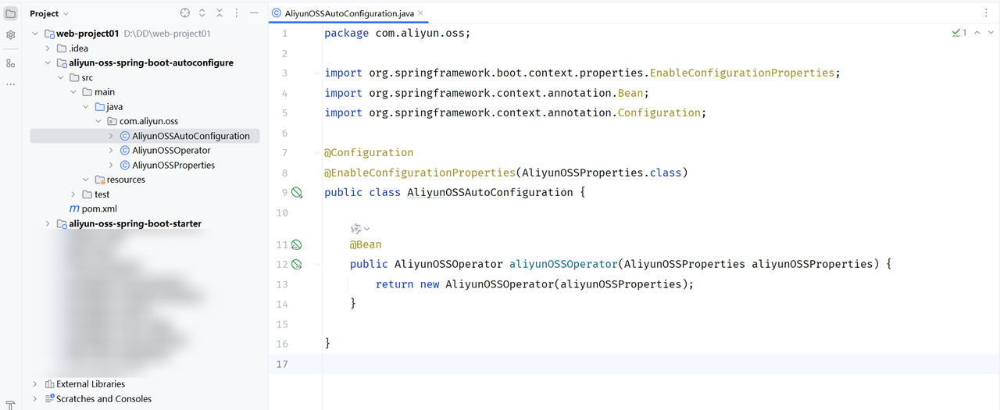

具体代码如下：

```java
package com.aliyun.oss;

import org.springframework.boot.context.properties.EnableConfigurationProperties;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;

@Configuration
@EnableConfigurationProperties(AliyunOSSProperties.class)
public class AliyunOSSAutoConfiguration {
    
    @Bean
    public AliyunOSSOperator aliyunOSSOperator(AliyunOSSProperties aliyunOSSProperties) {
        return new AliyunOSSOperator(aliyunOSSProperties);
    }
    
}
```

AliyunOSSOperator 的代码中需要增加一个有参构造，将 AliyunOSSProperties 对象传递给工具类。代码改造如下：

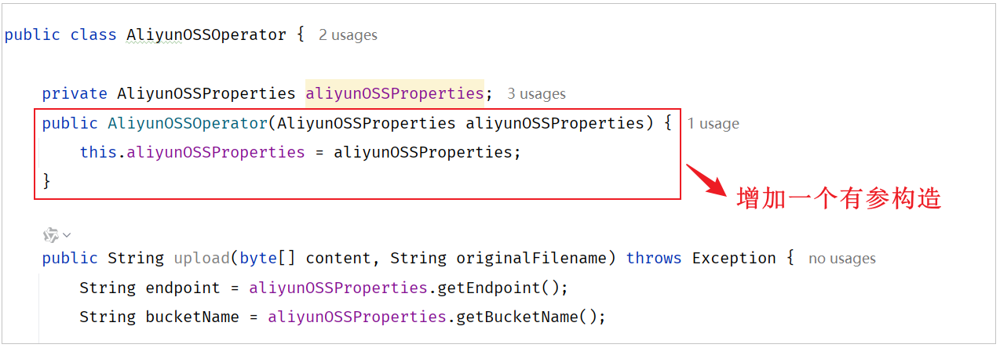

4). 在 aliyun-oss-spring-boot-autoconfigure 模块中的resources下，新建自动配置文件 META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports

将自动配置类的全类名，配置在文件中，这样在springboot启动的时候，就会加载到这份文件，并加载到其中的配置类了。

配置内容如下：

```java
com.aliyun.oss.AliyunOSSAutoConfiguration
```

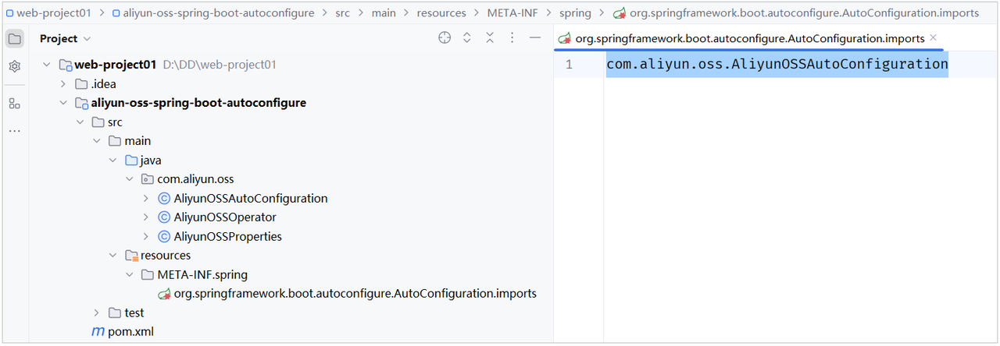

到此呢，这个 aliyun-oss-spring-boot-stater 就定义好了，哪里要想使用，就可以直接导入依赖，直接注入使用了。

##### 测试

阿里云OSS的starter我们刚才已经定义好了，接下来我们就来做一个测试。

**讲义提示**

> 今天的课程资料当中，提供了一个自定义starter的测试工程。我们直接打开文件夹，里面有一个测试工程。测试工程就是 springboot-autoconfiguration-test，我们只需要将测试工程直接导入到Idea当中即可。

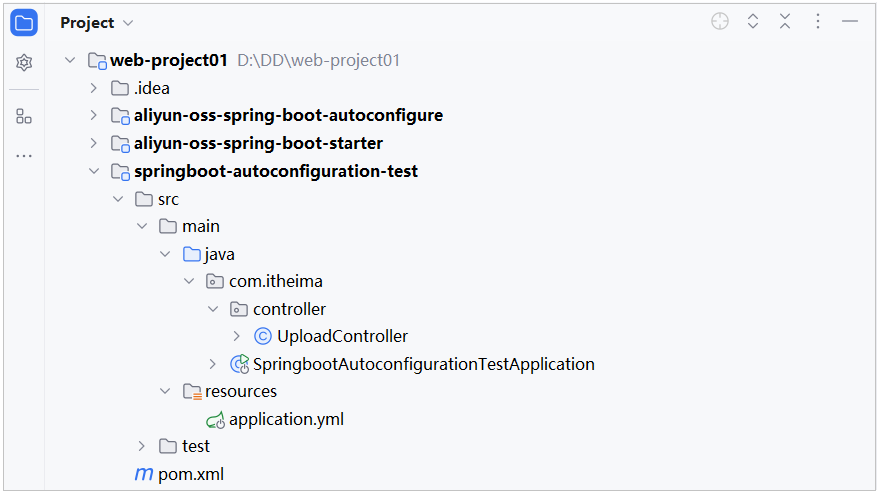

测试前准备：

1). 在导入的test工程中引入阿里云starter依赖

```xml
<dependency>
    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-oss-spring-boot-starter</artifactId>
    <version>0.0.1-SNAPSHOT</version>
</dependency>
```

2). 在导入的test工程中的 application.yml 中配置阿里云OSS的配置信息

```yaml
aliyun:
  oss:
    endpoint: https://oss-cn-beijing.aliyuncs.com
    bucketName: java422-web-ai
```

3). 在test工程中的 UploadController 类编写代码

```java
package com.itheima.controller;

import com.aliyun.oss.AliyunOSSOperator;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RestController;
import org.springframework.web.multipart.MultipartFile;

@RestController
public class UploadController {
    
    @Autowired
    private AliyunOSSOperator aliyunOSSOperator;
    
    @PostMapping("/upload")
    public String upload(MultipartFile image) throws Exception {
        //上传文件到阿里云 OSS
        String url = aliyunOSSOperator.upload(image.getBytes(), image.getOriginalFilename());
        return url;
    }
    
}
```

编写完代码后，我们启动当前的SpringBoot测试工程，使用Apifox工具进行文件上传：

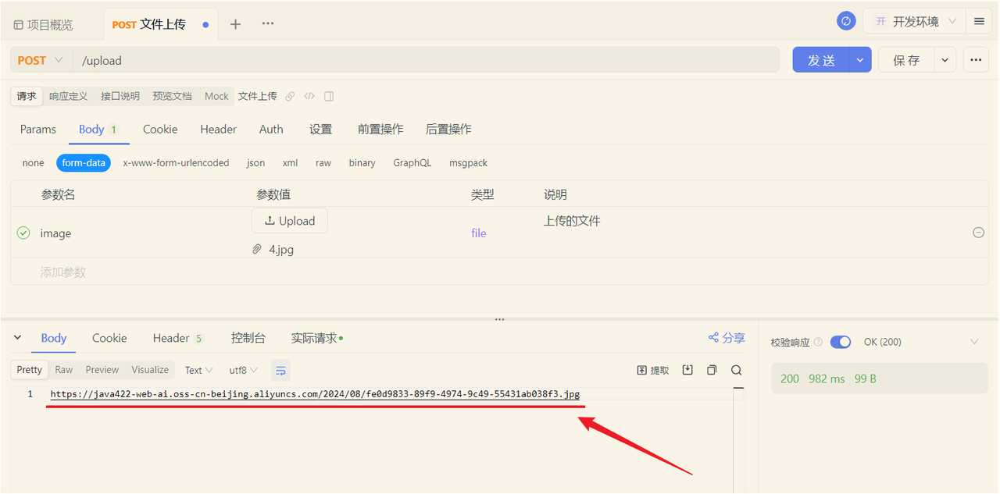

这样，我们就完成了starter的定义。在其他项目中要想使用，引入依赖，配置一下阿里云OSS的信息，就可以直接注入是用了 。

# Maven 高级

以下内容对应第二份讲义，继续保留原始顺序。

Web开发讲解完毕之后，我们再来学习Maven高级。其实在前面的课程当中，我们已经学习了Maven。

我们讲到 Maven 是一款构建和管理 Java 项目的工具。经过前面十几天 web 开发的学习，相信大家对于 Maven 这款工具的基本使用应该没什么问题了。我们掌握了 Maven 工具的基本使用之后，其实对于一些简单的项目的构建及管理基本上就没什么问题了。

但是如果我们需要开发一些中大型的项目，此时仅凭我们前面所学习的 Maven 的基础知识就比较难以应对了。所以我们接下来还需要学习 Maven 提供的一些高级的功能，这些功能在构建和管理 Java 项目的时候用的也是非常多的。

**讲义提示**

> Maven高级内容包括:

> - 分模块设计与开发

> - 继承与聚合

> - 私服

## 分模块设计与开发

> **补充｜模块边界。** 模块按稳定的职责和依赖方向拆分：公共模块放跨业务复用的模型与工具，业务模块依赖公共模块，避免公共模块反向依赖业务模块。拆分过细会增加构建和发布成本，应以独立演进和复用价值为依据。

### 介绍

所谓分模块设计，顾名思义指的就是我们在设计一个 Java 项目的时候，将一个 Java 项目拆分成多个模块进行开发。

1). 未分模块设计的问题

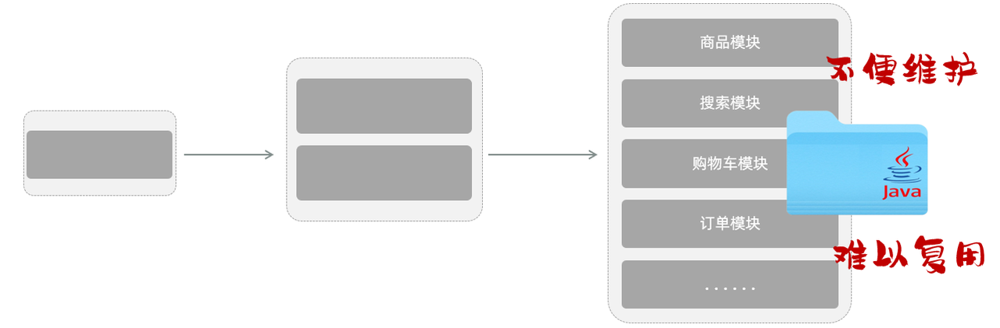

如果项目不分模块，也就意味着所有的业务代码是不是都写在这一个 Java 项目当中。随着这个项目的业务扩张，项目当中的业务功能可能会越来越多。

假如我们开发的是一个大型的电商项目，里面可能就包括了商品模块的功能、搜索模块的功能、购物车模块、订单模块、用户中心等等。这些所有的业务代码我们都在一个 Java 项目当中编写。

此时大家可以试想一下，假如我们开发的是一个大型的电商网站，这个项目组至少几十号甚至几百号开发人员，这些开发人员全部操作这一个 Java 项目。此时大家就会发现我们项目管理和维护起来将会非常的困难。而且大家再来看，假如在我们的项目当中，我们自己定义了一些通用的工具类以及通用的组件，而公司还有其他的项目组，其他项目组也想使用我们所封装的这些组件和工具类，其实是非常不方便的。因为 Java 项目当中包含了当前项目的所有业务代码，所以就造成了这里面所封装的一些组件会难以复用。

**讲义提示**

> 总结起来，主要两点问题：不方便项目的维护和管理、项目中的通用组件难以复用。

2). 分模块设计

分模块设计我们在进行项目设计阶段，就可以将一个大的项目拆分成若干个模块，每一个模块都是独立的。

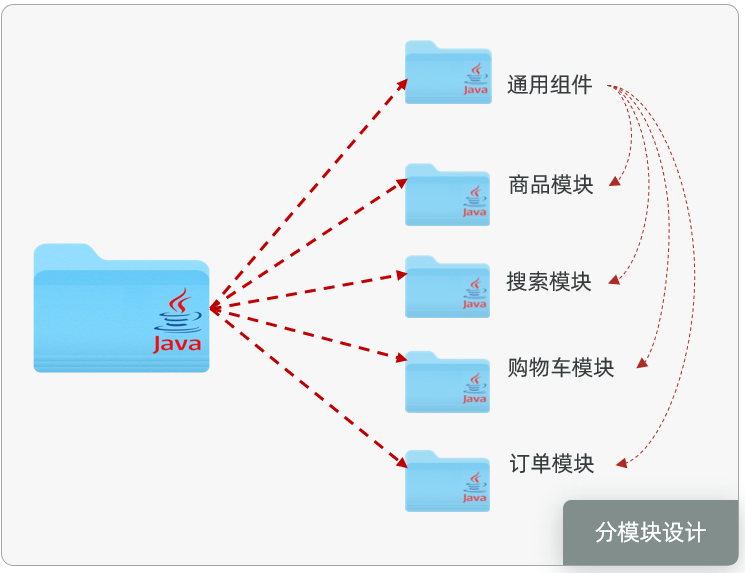

比如我们可以将商品的相关功能放在商品模块当中，搜索的相关业务功能我都封装在搜索模块当中，还有像购物车模块、订单模块。而为了组件的复用，我们也可以将项目当中的实体类、工具类以及我们定义的通用的组件都单独的抽取到一个模块当中。

如果当前这个模块，比如订单模块需要用到这些实体类以及工具类或者这些通用组件，此时直接在订单模块当中引入工具类的坐标就可以了。这样我们就将一个项目拆分成了若干个模块儿，这就是分模块儿设计。

分模块儿设计之后，大家再来看。我们在进行项目管理的时候，我就可以几个人一组，几个人来负责订单模块儿，另外几个人来负责购物车模块儿，这样更加便于项目的管理以及项目的后期维护。

而且分模块设计之后，如果我们需要用到另外一个模块的功能，我们直接依赖模块就可以了。比如商品模块、搜索模块、购物车订单模块都需要依赖于通用组件当中封装的一些工具类，我只需要引入通用组件的坐标就可以了。

**讲义提示**

> 分模块设计就是将项目按照功能/结构拆分成若干个子模块，方便项目的管理维护、拓展，也方便模块键的相互调用、资源共享。

### 策略

1. 策略一：按照功能模块拆分，比如：公共组件、商品模块、搜索模块、购物车模块、订单模块等。

1. 策略二：按层拆分，比如：公共组件、实体类、控制层、业务层、数据访问层。

1. 策略三：按照功能模块 + 层拆分。

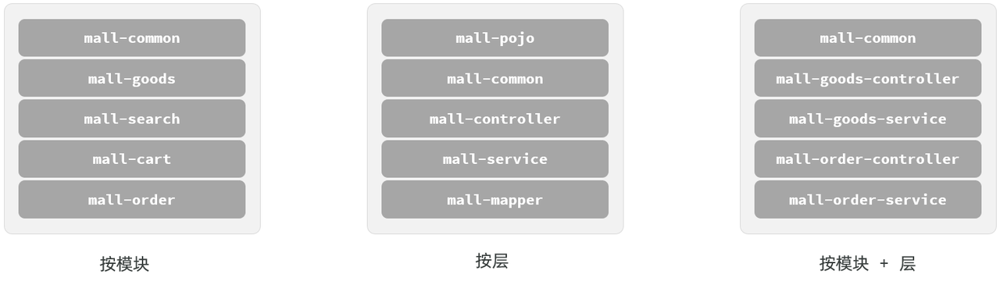

### 实践

#### 分析

好，我们明白了什么是分模块设计以及分模块设计的优势之后，接下来我们就来看一下我们之前所开发的案例工程。

我们可以看到在这个项目当中，除了我们所开发的部门管理以及员工管理、登录认证等相关业务功能以外，我们是不是也定义了一些实体类，也就是pojo包下存放的一些类，像分页结果的封装类PageBean、 统一响应结果Result，我们还定义了一些通用的工具类，像Jwts、阿里云OSS操作的工具类等等。

如果在当前公司的其他项目组当中，也想使用我们所封装的这些公共的组件，该怎么办？大家可以思考一下。

- 方案一：直接依赖我们当前项目 tlias-web-management ，但是存在两大缺点：

    - 这个项目当中包含所有的业务功能代码，而想共享的资源，仅仅是pojo下的实体类，以及 utils 下的工具类。如果全部都依赖进来，项目在启动时将会把所有的类都加载进来，会\*\*影响性能\*\*。

    - 如果直接把这个项目都依赖进来了，那也就意味着我们所有的业务代码都对外公开了，这个是非常\*\*不安全\*\*的。

- 方案二：分模块设计

    - 将pojo包下的实体类，抽取到一个maven模块中 tlias-pojo

    - 将utils包下的工具类，抽取到一个maven模块中 tlias-utils

    - 其他的业务代码，放在tlias-web-management这个模块中，在该模块中需要用到实体类pojo、工具类utils，直接引入对应的依赖即可。

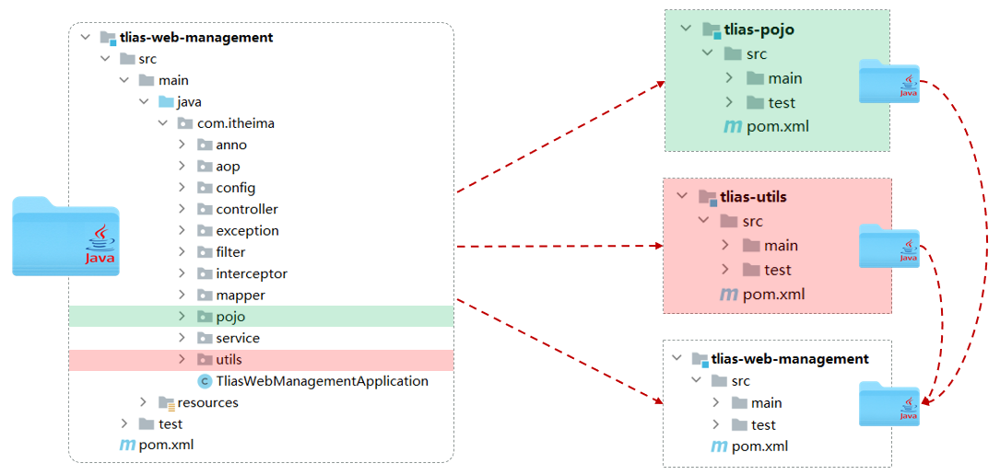

**讲义提示**

> 注意：分模块开发需要先针对模块功能进行设计，再进行编码。不会先将工程开发完毕，然后进行拆分。

> PS：当前我们是为了演示分模块开发，所以是基于我们前面开发的案例项目进行拆分的，实际中都是分模块设计，然后再开发的。

#### 实现

思路我们分析完毕，接下来，我们就根据我们分析的思路，按照如下模块进行拆分：

1. 创建maven模块 tlias-pojo，存放实体类

A. 创建一个正常的Maven模块，模块名 tlias-pojo

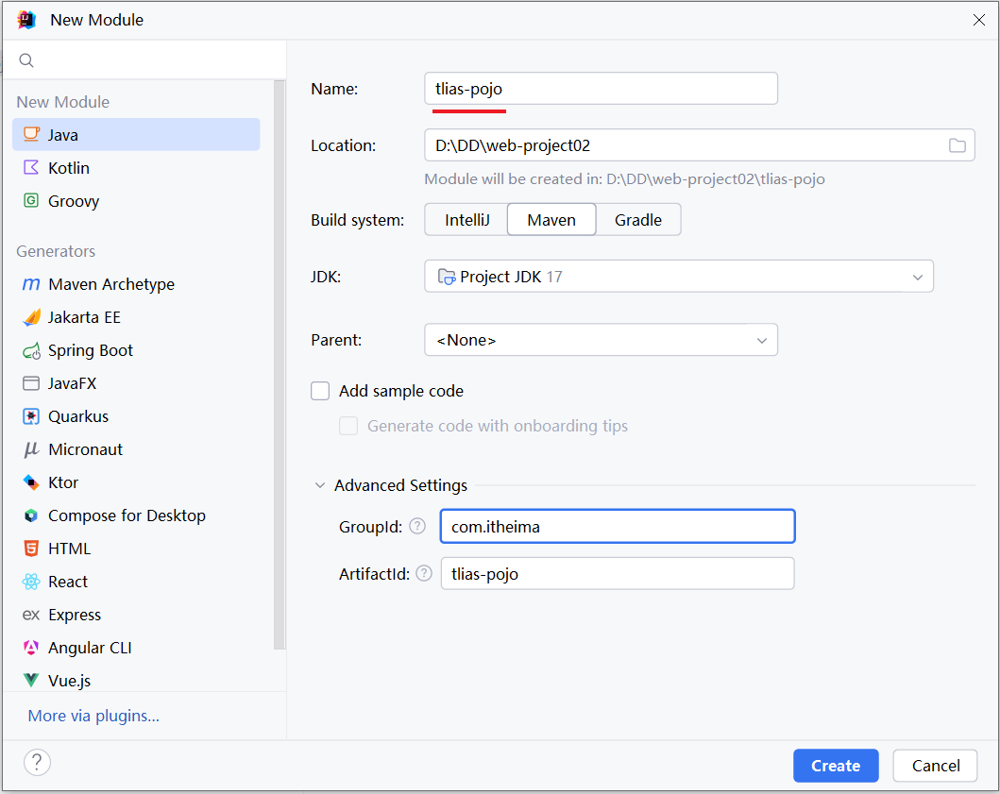

B. 然后在tlias-pojo中创建一个包 com.itheima.pojo (和原来案例项目中的pojo包名一致)

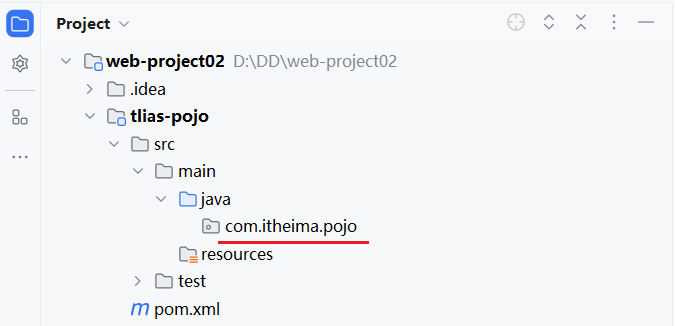

C. 将原来案例项目 tlias-web-management 中的pojo包下的实体类，复制到 tlias-pojo 模块中

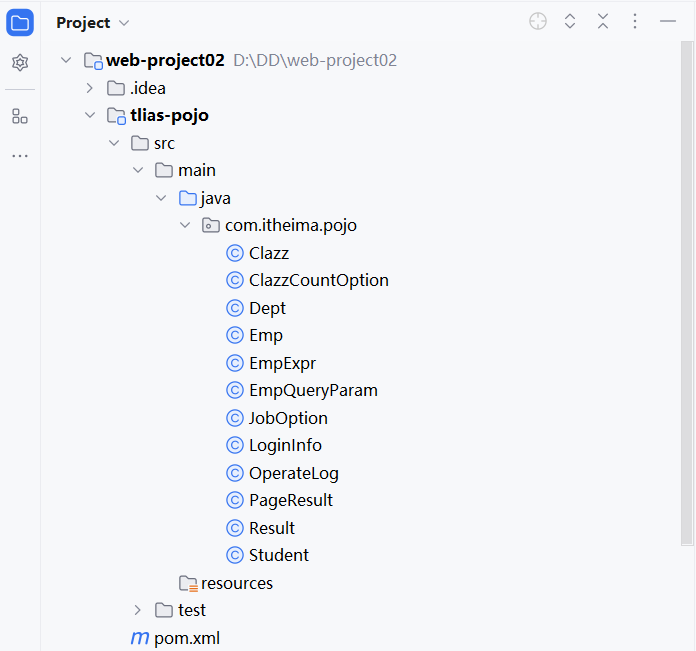

D. 在 tlias-pojo 模块的pom.xml文件中引入依赖

```xml
<dependencies>
    <dependency>
        <groupId>org.projectlombok</groupId>
        <artifactId>lombok</artifactId>
        <version>1.18.34</version>
    </dependency>
    
    <dependency>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter</artifactId>
        <version>3.2.8</version>
    </dependency>
</dependencies>
```

因为在实体类中，还用到了Spring框架中的 @DateTimeFormat 这样的注解，所以这里再引入一个springboot的基础起步依赖。

E. 删除原有案例项目 tlias-web-management 的pojo包【直接删除不要犹豫，我们已经将该模块拆分出去了】，然后在pom.xml中引入 tlias-pojo的依赖

```xml
<dependency>
    <groupId>com.itheima</groupId>
    <artifactId>tlias-pojo</artifactId>
    <version>1.0-SNAPSHOT</version>
</dependency>
```

2. 创建Maven模块 tlias-utils，存放相关工具类

A. 创建一个正常的Maven模块，模块名 tlias-utils

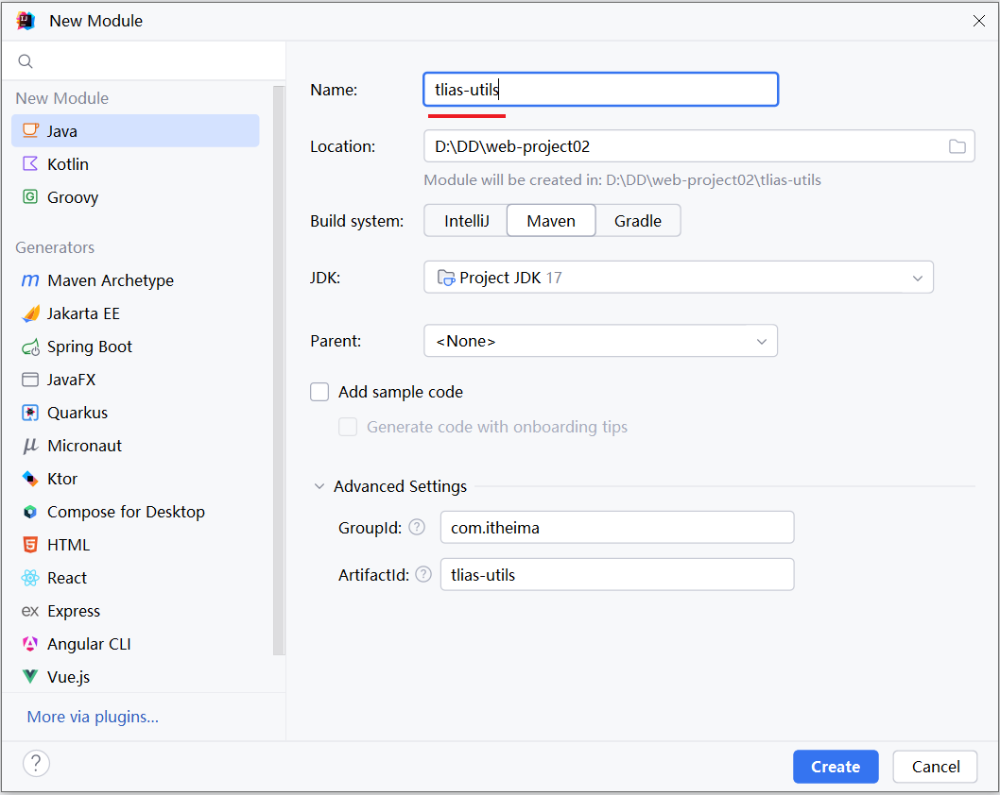

B. 然后在 tlias-utils 中创建一个包 com.itheima.utils (和原来案例项目中的utils包名一致)

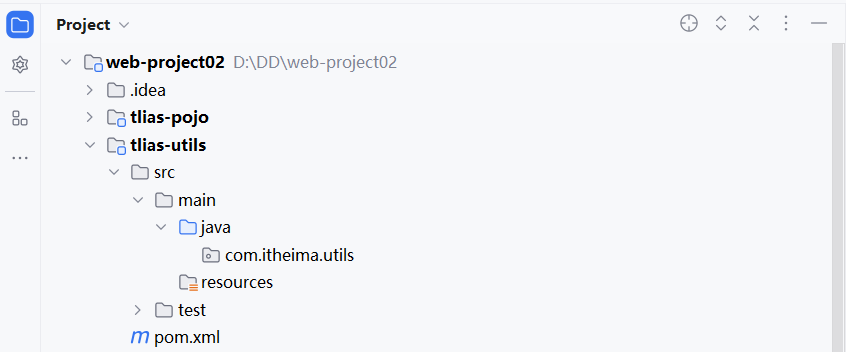

C. 将原来案例项目 tlias-web-management 中的util包下的实体类，复制到 tlias-utils 模块中

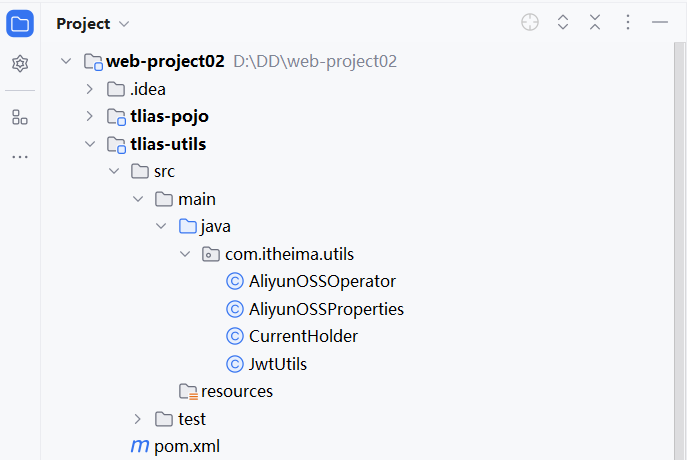

D. 在 tlias-utils 模块的 pom.xml 文件中引入依赖。

```xml
<dependencies>
    <!-- JWT依赖-->
    <dependency>
        <groupId>io.jsonwebtoken</groupId>
        <artifactId>jjwt</artifactId>
        <version>0.9.1</version>
    </dependency>

    <dependency>
        <groupId>com.aliyun.oss</groupId>
        <artifactId>aliyun-sdk-oss</artifactId>
        <version>3.17.4</version>
    </dependency>
    <dependency>
        <groupId>javax.xml.bind</groupId>
        <artifactId>jaxb-api</artifactId>
        <version>2.3.1</version>
    </dependency>
    <dependency>
        <groupId>javax.activation</groupId>
        <artifactId>activation</artifactId>
        <version>1.1.1</version>
    </dependency>
    <!-- no more than 2.3.3-->
    <dependency>
        <groupId>org.glassfish.jaxb</groupId>
        <artifactId>jaxb-runtime</artifactId>
        <version>2.3.3</version>
    </dependency>

    <dependency>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter</artifactId>
        <version>3.2.8</version>
    </dependency>

    <dependency>
        <groupId>org.projectlombok</groupId>
        <artifactId>lombok</artifactId>
        <version>1.18.34</version>
    </dependency>
</dependencies>
```

E. 删除原有案例项目 tlias-web-management 的util包【直接删除不要犹豫，我们已经将该模块拆分出去了】，然后在pom.xml中引入 tlias-utils 的依赖。

```xml
<dependency>
    <groupId>com.itheima</groupId>
    <artifactId>tlias-utils</artifactId>
    <version>1.0-SNAPSHOT</version>
</dependency>
```

到此呢，就已经完成了模块的拆分，拆分出了 tlias-pojo、tlias-utils、tlias-web-management ，如果其他项目中需要用到 pojo，或者 utils工具类，就可以直接引入依赖。

**讲义提示**

> - 什么是分模块设计：将项目按照功能拆分成若干个子模块

> - 为什么要分模块设计：方便项目的管理维护、扩展，也方便模块间的相互调用，资源共享

> - 注意事项：分模块设计需要先针对模块功能进行设计，再进行编码。不会先将工程开发完毕，然后进行拆分

## 继承与聚合

> **补充｜两个概念的区别。** Maven `parent` 用于继承配置和版本管理；`modules` 用于聚合构建多个子项目。父工程可以只做版本管理而不打包业务代码，聚合工程也可以与父工程是同一个 POM，但二者解决的问题不同。

在案例项目分模块开发之后啊，我们会看到 tlias-pojo、tlias-utils、tlias-web-management 中都引入了一个依赖 lombok 的依赖。我们在三个模块中分别配置了一次。

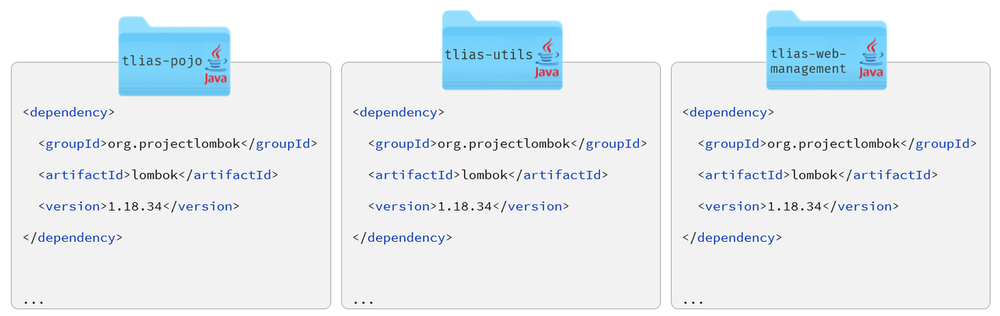

如果是做一个大型的项目，这三个模块当中重复的依赖可能会很多很多。如果每一个 Maven 模块里面，我们都来单独的配置一次，功能虽然能实现，但是配置是比较 繁琐 的 。

而接下来我们要讲解的 Maven 的继承用来解决这问题的。

### 继承

我们可以再创建一个父工程 tlias-parent ，然后让上述的三个模块 tlias-pojo、tlias-utils、tlias-web-management 都来继承这个父工程 。 然后再将各个模块中都共有的依赖，都提取到父工程 tlias-parent中进行配置，只要子工程继承了父工程，依赖它也会继承下来，这样就无需在各个子工程中进行配置了。

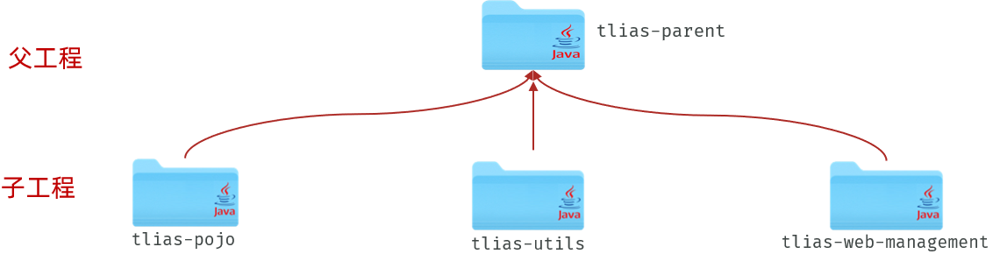

- 概念：继承描述的是两个工程间的关系，与java中的继承相似，子工程可以继承父工程中的配置信息，常见于依赖关系的继承。

- 作用：简化依赖配置、统一管理依赖

- 实现：

```xml
<parent>
    <groupId>...</groupId>
    <artifactId>...</artifactId>
    <version>...</version>
    <relativePath>....</relativePath>
</parent>
```

这是我们在这里先介绍一下什么是继承以及继承的作用，以及在 maven 当中如何来实现这层继承关系。接下来我们就来创建这样一个 parent 父工程，我们就可以将各个子工程当中共有的这部分依赖统一的定义在父工程 parent 当中，从而来简化子工程的依赖配置。接下来我们来看一下具体的操作步骤。

我们在这里先介绍一下什么是继承以及继承的作用，以及在 maven 当中如何来实现这层继承关系。接下来我们就来创建这样一个 parent 父工程，我们就可以将各个子工程当中共有的这部分依赖，统一的定义在父工程 parent 当中，从而来简化子工程的依赖配置。

#### 继承关系

##### 思路分析

我们当前的项目 tlias-web-management，还稍微有一点特殊，因为是一个springboot项目，而所有的springboot项目都有一个统一的父工程，就是 spring-boot-starter-parent。 与java语言类似，Maven不支持多继承，一个maven项目只能继承一个父工程，如果继承了spring-boot-starter-parent，就没法继承我们自己定义的父工程 tlias-parent了。

那我们怎么来解决这个问题呢？

那此时，大家可以想一下，Java虽然不支持多继承，但是可以支持多重继承，比如：A 继承 B， B 继承C。 那在Maven中也是支持多重继承的，所以呢，我们就可以让 我们自己创建的三个模块，都继承 tlias-parent，而 tlias-parent 再继承 spring-boot-starter-parent，就可以了。 具体结构如下：

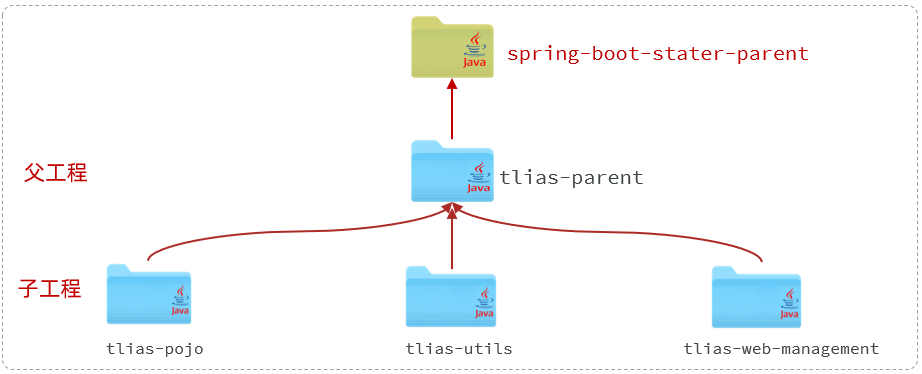

##### 实现

1). 创建maven模块 tlias-parent ，该工程为父工程，设置打包方式pom(默认jar)。

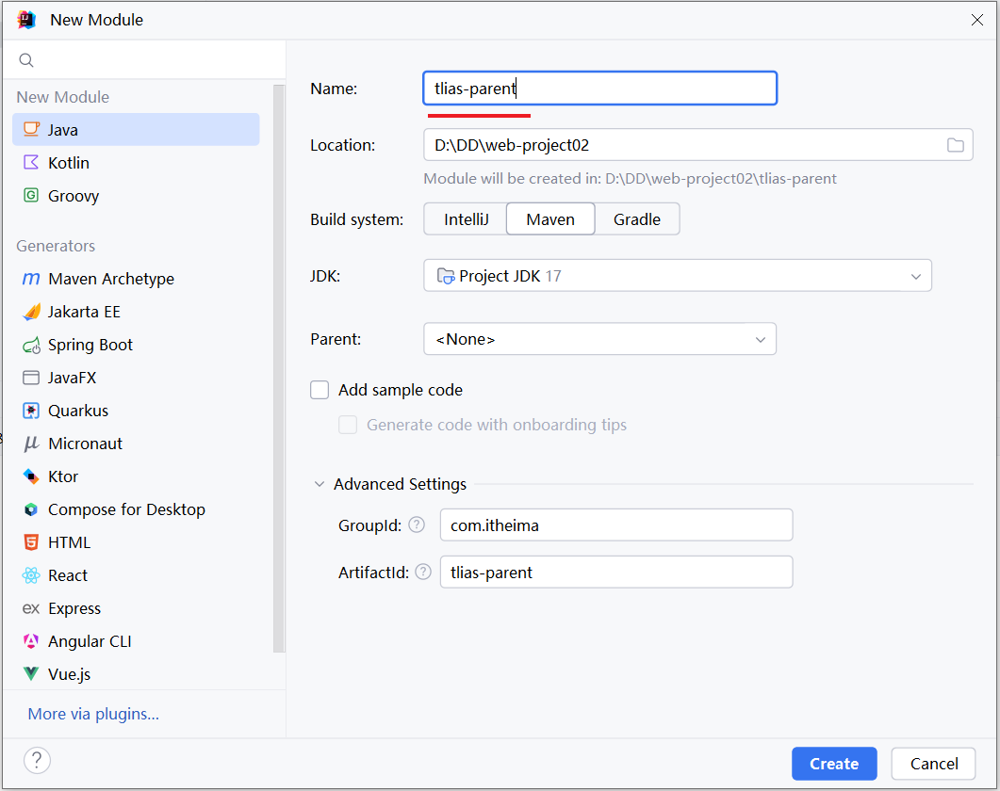

工程结构如下（src目录不需要，直接删除）：

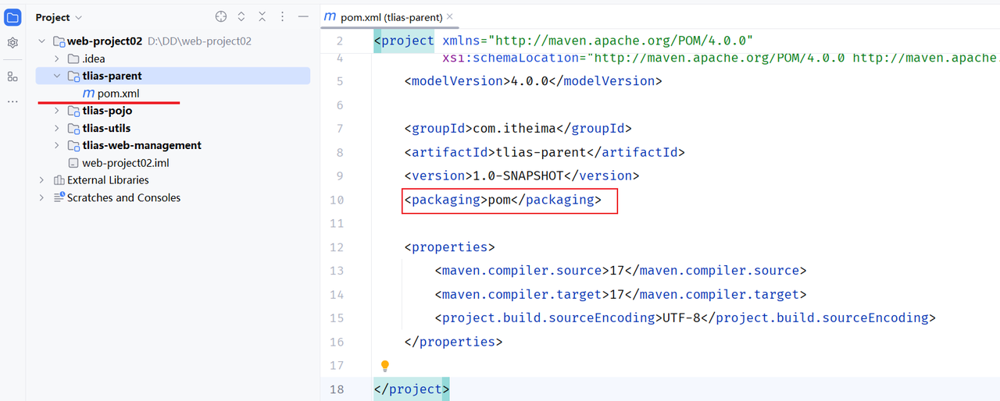

父工程tlias-parent的 pom.xml 文件配置如下：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 http://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>

    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.itheima</groupId>
    <artifactId>tlias-parent</artifactId>
    <version>1.0-SNAPSHOT</version>
    <packaging>pom</packaging>

    <properties>
        <maven.compiler.source>17</maven.compiler.source>
        <maven.compiler.target>17</maven.compiler.target>
        <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
    </properties>

</project>
```

**讲义提示**

> Maven打包方式：

> - jar：普通模块打包，springboot项目基本都是jar包（内嵌tomcat运行）

> - war：普通web程序打包，需要部署在外部的tomcat服务器中运行

> - pom：父工程或聚合工程，该模块不写代码，仅进行依赖管理

2). 在子工程（tlias-pojo、tlias-utils、tlias-web-management）的pom.xml文件中，配置继承关系。

```xml
<parent>
    <groupId>com.itheima</groupId>
    <artifactId>tlias-parent</artifactId>
    <version>1.0-SNAPSHOT</version>
    <relativePath>../tlias-parent/pom.xml</relativePath>
</parent>

<artifactId>tlias-utils</artifactId>
<version>1.0-SNAPSHOT</version>
```

这里是以 tlias-utils 为例，指定了其父工程。其他的模块，都是相同的配置方式。

**讲义提示**

> 注意：

> - 在子工程中，配置了继承关系之后，坐标中的groupId是可以省略的，因为会自动继承父工程的 。

> - relativePath指定父工程的pom文件的相对位置（如果不指定，将从本地仓库/远程仓库查找该工程）。

>     - ../ 代表的上一级目录

3). 在父工程中配置各个工程共有的依赖（子工程会自动继承父工程的依赖）。

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 http://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>

    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.itheima</groupId>
    <artifactId>tlias-parent</artifactId>
    <version>1.0-SNAPSHOT</version>
    <packaging>pom</packaging>

    <properties>
        <maven.compiler.source>17</maven.compiler.source>
        <maven.compiler.target>17</maven.compiler.target>
        <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter</artifactId>
            <version>3.2.8</version>
        </dependency>

        <dependency>
            <groupId>org.projectlombok</groupId>
            <artifactId>lombok</artifactId>
            <version>1.18.34</version>
        </dependency>
    </dependencies>

</project>
```

此时，我们已经将各个子工程中共有的依赖（lombok 和 spring-boot-starter），都定义在了父工程中，子工程中的这一项依赖，就可以直接删除了。删除之后，我们会看到父工程中配置的依赖 lombok，子工程直接继承下来了。

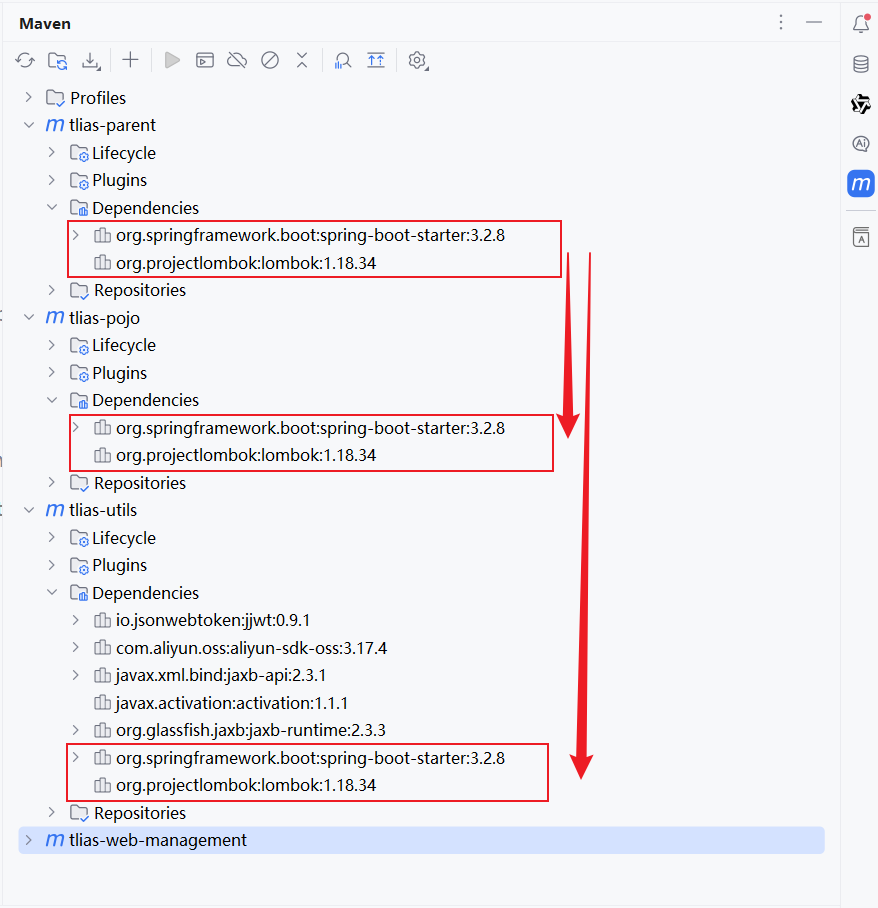

**讲义提示**

> 工程结构说明:

> - 我们当前的项目结构为：

>     - tlias-parent

>     - tlias-pojo

>     - tlias-utils

>     - tlias-web-management

> 因为我们是项目开发完毕之后，给大家基于现有项目拆分的各个模块，tlias-web-management 已经存在了，然后再创建各个模块与父工程，所以父工程与模块之间是平级的。

**讲义提示**

> 工程结构说明:

> - 而实际项目中，可能还会见到下面的工程结构：

>     - tlias-parent

>         - tlias-pojo

>         - tlias-utils

>         - tlias-web-management

> 而在真实的企业开发中，都是先设计好模块之后，再开始创建模块，开发项目。 那此时呢，一般都会先创建父工程 tlias-parent，然后将创建的各个子模块，都放在父工程parent下面。 这样层级结构会更加清晰一些。

PS：上面两种工程结构，都是可以正常使用的，没有一点问题。 只不过，第二种结构，看起来，父子工程结构更加清晰、更加直观。

#### 版本锁定

##### 场景

如果项目中各个模块中都公共的这部分依赖，我们可以直接定义在父工程中，从而简化子工程的配置。 然而在项目开发中，还有一部分依赖，并不是各个模块都共有的，可能只是其中的一小部分模块中使用到了这个依赖。

比如：在tlias-web-management、tlias-web-system、tlias-web-report这三个子工程中，都使用到了jwt的依赖。 但是 tlias-pojo、tlias-utils中并不需要这个依赖，那此时，这个依赖，我们不会直接配置在父工程 tlias-parent中，而是哪个模块需要，就在哪个模块中配置。

而由于是一个项目中的多个模块，那多个模块中，我们要使用的同一个依赖的版本要一致，这样便于项目依赖的统一管理。比如：这个jwt依赖，我们都使用的是 0.9.1 这个版本。

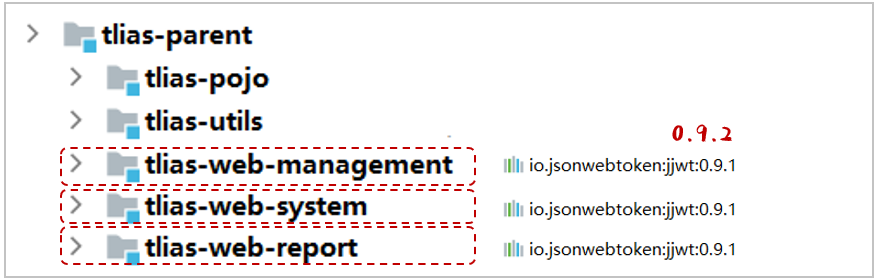

那假如说，我们项目要升级，要使用到jwt最新版本 0.9.2 中的一个新功能，那此时需要将依赖的版本升级到0.9.2，那此时该怎么做呢 ？

第一步：去找当前项目中所有的模块的pom.xml配置文件，看哪些模块用到了jwt的依赖。

第二步：找到这个依赖之后，将其版本version，更换为 0.9.2。

问题：如果项目拆分的模块比较多，每一次更换版本，我们都得找到这个项目中的每一个模块，一个一个的更改。 很容易就会出现，遗漏掉一个模块，忘记更换版本的情况。

那我们又该如何来解决这个问题，如何来统一管理各个依赖的版本呢？

答案：Maven的版本锁定功能。

##### 介绍

在maven中，可以在父工程的pom文件中通过 <dependencyManagement> 来统一管理依赖版本。

- 父工程：

```xml
<!--统一管理依赖版本-->
<dependencyManagement>
    <dependencies>
        <!--JWT令牌-->
        <dependency>
            <groupId>io.jsonwebtoken</groupId>
            <artifactId>jjwt</artifactId>
            <version>0.9.1</version>
        </dependency>
    </dependencies>
</dependencyManagement>
```

- 子工程：

```xml
<dependencies>
    <!--JWT令牌-->
    <dependency>
        <groupId>io.jsonwebtoken</groupId>
        <artifactId>jjwt</artifactId>
    </dependency>
</dependencies>
```

**讲义提示**

> 注意：

> - 在父工程中所配置的 <dependencyManagement> 只能统一管理依赖版本，并不会将这个依赖直接引入进来。 这点和 <dependencies> 是不同的。

> - 子工程要使用这个依赖，还是需要引入的，只是此时就无需指定 <version> 版本号了，父工程统一管理。变更依赖版本，只需在父工程中统一变更。

##### 实现

接下来，我们就可以将 tlias-utils 模块中单独配置的依赖，将其版本统一交给 tlias-parent 进行统一管理。

具体步骤如下：

1). tlias-parent 中的配置

```xml
<dependencyManagement>
    <dependencies>
        <!-- JWT依赖-->
        <dependency>
            <groupId>io.jsonwebtoken</groupId>
            <artifactId>jjwt</artifactId>
            <version>0.9.1</version>
        </dependency>

        <dependency>
            <groupId>com.aliyun.oss</groupId>
            <artifactId>aliyun-sdk-oss</artifactId>
            <version>3.17.4</version>
        </dependency>
        <dependency>
            <groupId>javax.xml.bind</groupId>
            <artifactId>jaxb-api</artifactId>
            <version>2.3.1</version>
        </dependency>
        <dependency>
            <groupId>javax.activation</groupId>
            <artifactId>activation</artifactId>
            <version>1.1.1</version>
        </dependency>
        <!-- no more than 2.3.3-->
        <dependency>
            <groupId>org.glassfish.jaxb</groupId>
            <artifactId>jaxb-runtime</artifactId>
            <version>2.3.3</version>
        </dependency>
    </dependencies>
</dependencyManagement>
```

2). tlias-utils 中的pom.xml配置

如果依赖的版本已经在父工程进行了统一管理，所以在子工程中就无需再配置依赖的版本了。

```xml
<dependencies>
    <!-- JWT依赖-->
    <dependency>
        <groupId>io.jsonwebtoken</groupId>
        <artifactId>jjwt</artifactId>
    </dependency>

    <dependency>
        <groupId>com.aliyun.oss</groupId>
        <artifactId>aliyun-sdk-oss</artifactId>
    </dependency>
    <dependency>
        <groupId>javax.xml.bind</groupId>
        <artifactId>jaxb-api</artifactId>
    </dependency>
    <dependency>
        <groupId>javax.activation</groupId>
        <artifactId>activation</artifactId>
    </dependency>
    <!-- no more than 2.3.3-->
    <dependency>
        <groupId>org.glassfish.jaxb</groupId>
        <artifactId>jaxb-runtime</artifactId>
    </dependency>
</dependencies>
```

**讲义提示**

> 我们之所以，在springboot项目中很多时候，引入依赖坐标，都不需要指定依赖的版本 <version> ，是因为在父工程 spring-boot-starter-parent中已经通过 <dependencyManagement>对依赖的版本进行了统一的管理维护。

##### 属性配置

我们也可以通过自定义属性及属性引用的形式，在父工程中将依赖的版本号进行集中管理维护。

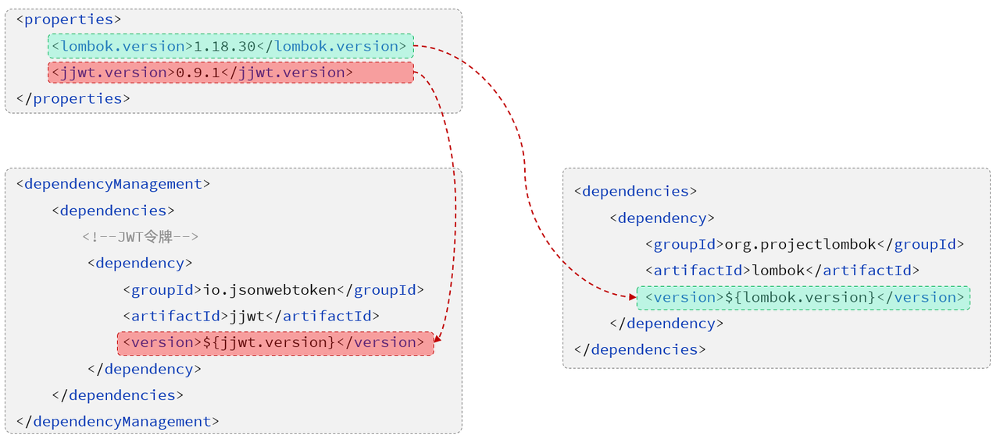

具体语法为：

1). 自定义属性

```xml
<properties>
    <lombok.version>1.18.34</lombok.version>
</properties>
```

2). 引用属性

```xml
<dependency>
    <groupId>org.projectlombok</groupId>
    <artifactId>lombok</artifactId>
    <version>${lombok.version}</version>
</dependency>
```

接下来，我们就可以在父工程中，将所有的版本号，都集中管理维护起来。

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 http://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>

    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.8</version>
        <relativePath/> <!-- lookup parent from repository -->
    </parent>

    <groupId>com.itheima</groupId>
    <artifactId>tlias-parent</artifactId>
    <version>1.0-SNAPSHOT</version>
    <packaging>pom</packaging>

    <properties>
        <maven.compiler.source>17</maven.compiler.source>
        <maven.compiler.target>17</maven.compiler.target>
        <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>

        <spring-boot.version>3.2.8</spring-boot.version>
        <lombok.version>1.18.34</lombok.version>
        <jwt.version>0.9.1</jwt.version>
        <aliyun.oss.version>3.17.4</aliyun.oss.version>
        <jaxb.version>2.3.1</jaxb.version>
        <javax.activation.version>1.1.1</javax.activation.version>
        <jaxb.runtime.version>2.3.3</jaxb.runtime.version>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter</artifactId>
            <version>${spring-boot.version}</version>
        </dependency>

        <dependency>
            <groupId>org.projectlombok</groupId>
            <artifactId>lombok</artifactId>
            <version>${lombok.version}</version>
        </dependency>
    </dependencies>

    <dependencyManagement>
        <dependencies>
            <!-- JWT依赖-->
            <dependency>
                <groupId>io.jsonwebtoken</groupId>
                <artifactId>jjwt</artifactId>
                <version>${jwt.version}</version>
            </dependency>

            <dependency>
                <groupId>com.aliyun.oss</groupId>
                <artifactId>aliyun-sdk-oss</artifactId>
                <version>${aliyun.oss.version}</version>
            </dependency>
            <dependency>
                <groupId>javax.xml.bind</groupId>
                <artifactId>jaxb-api</artifactId>
                <version>${jaxb.version}</version>
            </dependency>
            <dependency>
                <groupId>javax.activation</groupId>
                <artifactId>activation</artifactId>
                <version>${javax.activation.version}</version>
            </dependency>
            <!-- no more than 2.3.3-->
            <dependency>
                <groupId>org.glassfish.jaxb</groupId>
                <artifactId>jaxb-runtime</artifactId>
                <version>${jaxb.runtime.version}</version>
            </dependency>
        </dependencies>
    </dependencyManagement>

</project>
```

版本集中管理之后，我们要想修改依赖的版本，就只需要在父工程中自定义属性的位置，修改对应的属性值即可。

**讲义提示**

> 面试题：<dependencyManagement> 与 <dependencies> 的区别是什么?

> - <dependencies> 是直接依赖，在父工程配置了依赖，子工程会直接继承下来。

> - <dependencyManagement> 是统一管理依赖版本，不会直接依赖，还需要在子工程中引入所需依赖(无需指定版本)

### 聚合

分模块设计与开发之后啊，我们的项目被拆分为多个模块，而模块之间的关系，可能错综复杂。 那就比如我们当前的案例项目，结构如下（相对还是比较简单的）：

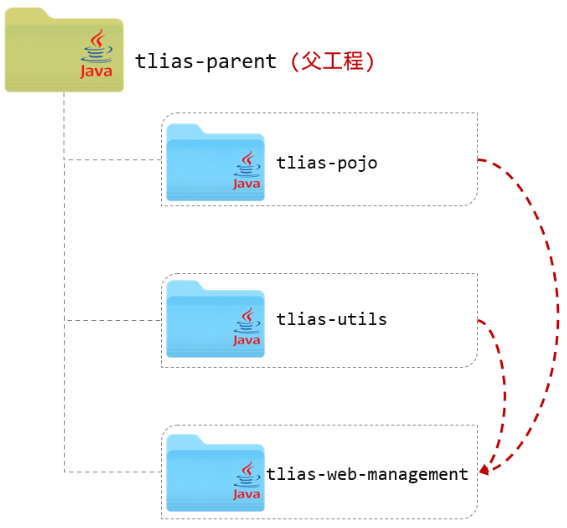

此时，tlias-web-management 模块的父工程是 tlias-parent，该模块又依赖了 tlias-pojo、tlias-utils 模块。 那此时，我们要想将 tlias-web-management 模块打包，是比较繁琐的。因为在进行项目打包时，maven会从本地仓库中来查找 tlias-parent 父工程，以及它所依赖的模块 tlias-pojo、tlias-utils，而本地仓库目前是没有这几个依赖的。

所以，我们再打包tlias-web-management 模块前，需要将 tlias-parent、tlias-pojo、tlias-utils 分别执行install生命周期安装到maven的本地仓库，然后再针对于 tlias-web-management 模块执行package进行打包操作。

那此时，大家试想一下，如果开发一个大型项目，拆分的模块很多，模块之间的依赖关系错综复杂，那此时要进行项目的打包、安装操作，是非常繁琐的。 而我们接下来，要讲解的maven的聚合就是来解决这个问题的，通过maven的聚合就可以轻松实现项目的一键构建（清理、编译、测试、打包、安装等）。

#### 介绍

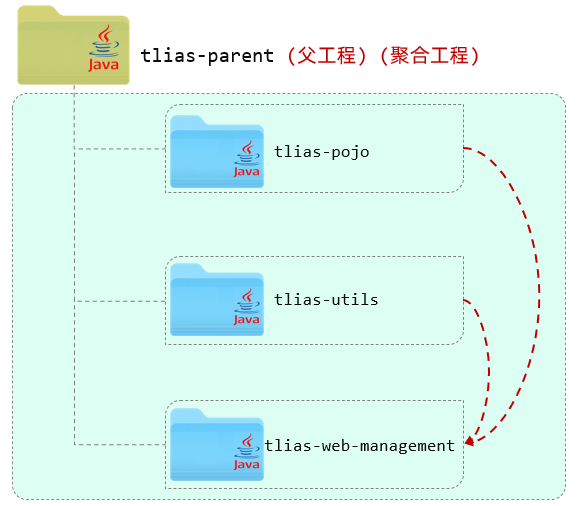

- 聚合：将多个模块组织成一个整体，同时进行项目的构建。

- 聚合工程：一个不具有业务功能的“空”工程（有且仅有一个pom文件） 【PS：一般来说，继承关系中的父工程与聚合关系中的聚合工程是同一个】

- 作用：快速构建项目（无需根据依赖关系手动构建，直接在聚合工程上构建即可）

#### 实现

在maven中，我们可以在聚合工程中通过 <moudules> 设置当前聚合工程所包含的子模块的名称。我们可以在 tlias-parent中，添加如下配置，来指定当前聚合工程，需要聚合的模块：

```xml
<!-- 聚合其他模块 -->
<modules>
    <module>../tlias-pojo</module>
    <module>../tlias-utils</module>
    <module>../tlias-web-management</module>
</modules>
```

那此时，我们要进行编译、打包、安装操作，就无需在每一个模块上操作了。只需要在聚合工程上，统一进行操作就可以了。

测试：执行在聚合工程 tlias-parent 中执行 package 打包指令

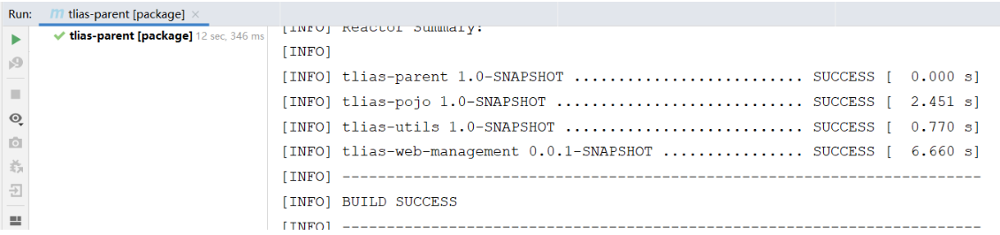

那 tlias-parent 中所聚合的其他模块全部都会执行 package 指令，这就是通过聚合实现项目的一键构建（一键清理clean、一键编译compile、一键测试test、一键打包package、一键安装install等）。

### 继承与聚合对比

- 作用

    - 聚合用于快速构建项目

    - 继承用于简化依赖配置、统一管理依赖

- 相同点：

    - 聚合与继承的pom.xml文件打包方式均为pom，通常将两种关系制作到同一个pom文件中

    - 聚合与继承均属于设计型模块，并无实际的模块内容

- 不同点：

    - 聚合是在聚合工程中配置关系，聚合可以感知到参与聚合的模块有哪些

    - 继承是在子模块中配置关系，父模块无法感知哪些子模块继承了自己

## 私服

> **补充｜仓库安全。** 私服同时承担代理中央仓库、缓存外部依赖和发布内部构件的职责。账号密码应放在 Maven `settings.xml` 的 server 配置或 CI 密钥中，并按仓库权限最小化；不要把认证信息写进项目 POM。

前面我们在讲解多模块开发的时候，我们讲到我们所拆分的模块是可以在同一个公司各个项目组之间进行资源共享的。这个模块的资源共享，就需要通过我们接下来所讲解的 Maven 的私服来实现。

首先我们先介绍一下什么是私服，以及它的作用是什么。再来介绍一下我们如何将每位模块打包上传到私服，以及从私服当中来下载。

### 场景

在介绍什么是私服之前，我们先来分析一下同一个公司，两个项目组之间如何基于私服进行资源的共享。

假设现在有两个团队，A 和 B。 A 开发了一个模块 tlias-utils，模块开发完毕之后，将模块打成jar包，并安装到了A的本地仓库。

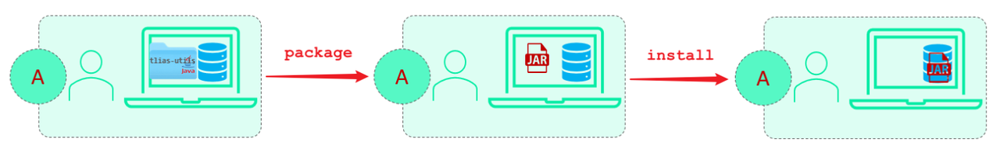

那此时，该公司的B团队开发项目时，要想使用 tlias-utils 中提供的工具类，该怎么办呢？ 对于maven项目来说，是不是在pom.xml文件中引入 tlias-utils的坐标就可以了呢？

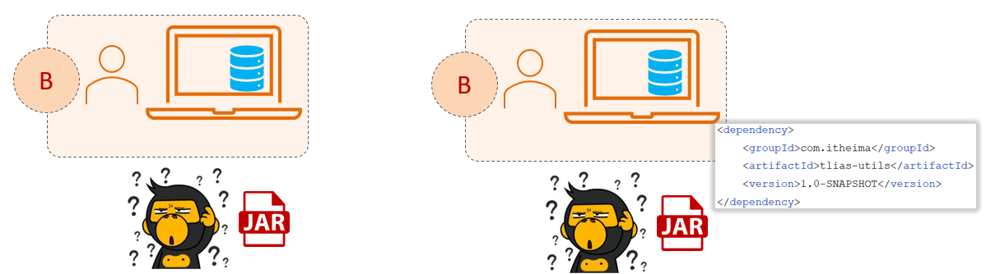

大家可以思考一下，当B团队在maven项目的pom.xml配置文件中引入了依赖的坐标之后，maven是如何查找这个依赖的？ 查找顺序为：

1). 本地仓库：本地仓库中是没有这个依赖jar包的。

2). 远程中央仓库：由于该模块时自己公司开发的，远程仓库中也没有这个依赖。

因为目前tlias-utils这个依赖，还在A的本地仓库中的。 B电脑上的maven项目，是不可能找得到A电脑上maven本地仓库的jar包的。  那此时，大家可能会有一个想法：因为A和B都会连接中央仓库，我们可以将A本地仓库的jar包，直接上传到中央仓库，然后B从中央仓库中下载tlias-utils这个依赖。

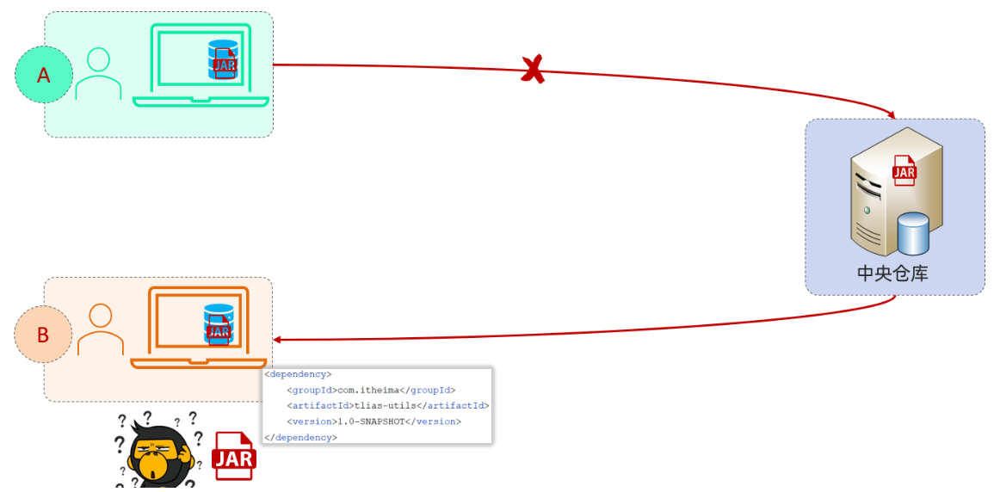

这个想法很美好，但是现实很残酷。这个方案是行不通的，因为中央仓库全球只有一个，不是什么人都可以往中央仓库中来上传jar包的，我们是没有权限操作的。

那此时，maven的私服就出场了，私服其实就是架设在公司局域网内部的一台服务器，就是一种特殊的远程仓库。

有了私服之后，各个团队就可以直接来连接私服了。 A 连接上私服之后，他就可以把jar包直接上传到私服当中。我公司自己内部搭建的服务器，我是不是有权限操作呀，把jar包上传到私服之后，我让 B 团队的所有开发人员也连接同一台私服。连接上这一台私服之后，他就会根据坐标的信息，直接从私服当中将对应的jar包下载到自己的本地仓库，这样就可以使用到依赖当中所提供的一些工具类了。这样我们就可以通过私服来完成资源的共享。

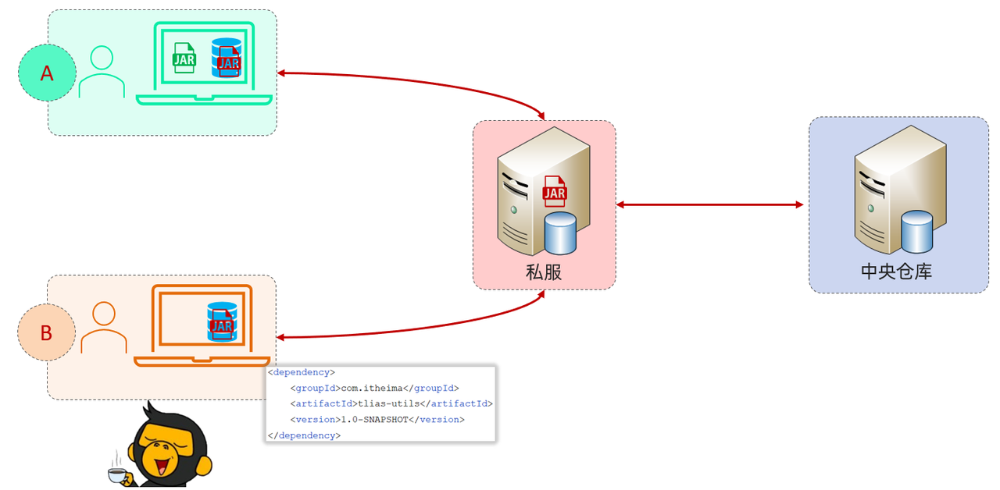

而如果我们在项目中需要使用其他第三方提供的依赖，如果本地仓库没有，也会自动连接私服下载，如果私服没有，私服此时会自动连接中央仓库，去中央仓库中下载依赖，然后将下载的依赖存储在私服仓库及本地仓库中。

### 介绍

- 私服：是一种特殊的远程仓库，它是架设在局域网内的仓库服务，用来代理位于外部的中央仓库，用于解决团队内部的资源共享与资源同步问题。

- 依赖查找顺序：

    - 本地仓库

    - 私服仓库

    - 中央仓库

- 注意事项：私服在企业项目开发中，一个项目/公司，只需要一台即可（无需我们自己搭建，会使用即可）。

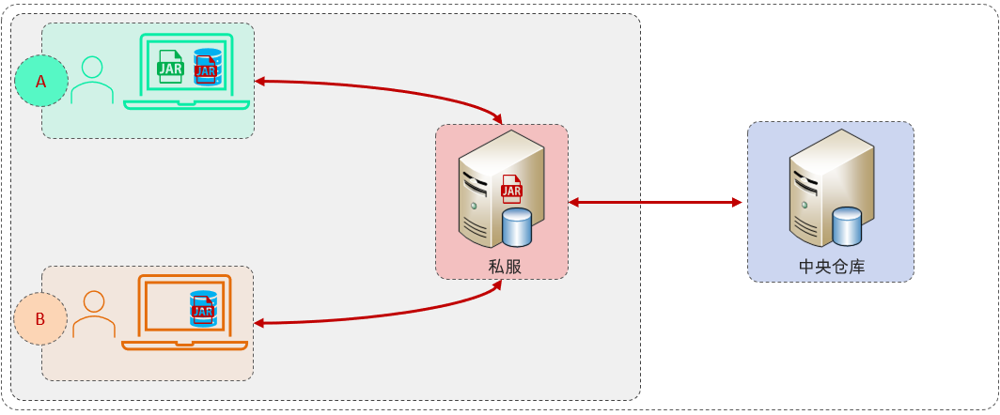

### 资源上传与下载

#### 步骤分析

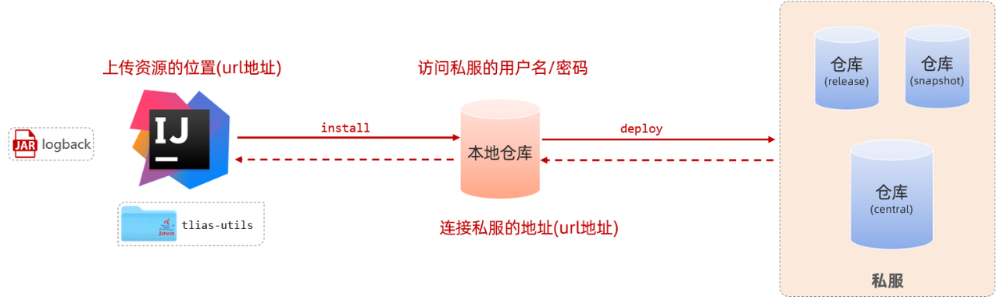

资源上传与下载，我们需要做三步配置，执行一条指令。

- 第一步配置：在maven的配置文件中配置访问私服的用户名、密码。

- 第二步配置：在maven的配置文件中配置连接私服的地址(url地址)。

- 第三步配置：在项目的pom.xml文件中配置上传资源的位置(url地址)。

- 配置好了上述三步之后，要上传资源到私服仓库，就执行执行maven生命周期：deploy。

**讲义提示**

> 私服仓库说明：

> - RELEASE：存储自己开发的RELEASE发布版本的资源。

> - SNAPSHOT：存储自己开发的SNAPSHOT发布版本的资源。

> - Central：存储的是从中央仓库下载下来的依赖。

**讲义提示**

> 项目版本说明：

> - RELEASE(发布版本)：功能趋于稳定、当前更新停止，可以用于发行的版本，存储在私服中的RELEASE仓库中。

> - SNAPSHOT(快照版本)：功能不稳定、尚处于开发中的版本，即快照版本，存储在私服的SNAPSHOT仓库中。

#### 具体操作

私服已经搭建好了，已经启动起来了，我们可以访问私服测试：http://localhost:8081。

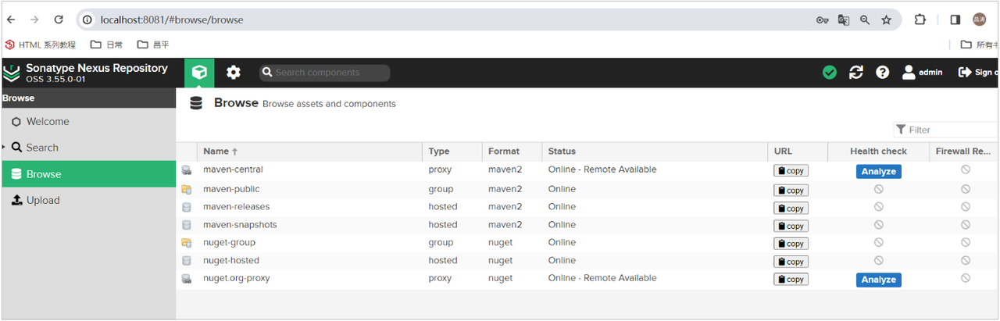

私服准备好了之后，我们要做如下几步配置：

1. 设置私服的访问用户名/密码（在自己maven安装目录下的conf/settings.xml中的servers中配置）

```xml
<server>
    <id>maven-releases</id>
    <username>admin</username>
    <password>admin</password>
</server>
    
<server>
    <id>maven-snapshots</id>
    <username>admin</username>
    <password>admin</password>
</server>
```

2. 设置私服依赖下载的仓库组地址（在自己maven安装目录下的conf/settings.xml中的mirrors、profiles中配置）

```xml
<mirror>
    <id>maven-public</id>
    <mirrorOf>*</mirrorOf>
    <url>http://localhost:8081/repository/maven-public/</url>
</mirror>
<profile>
    <id>allow-snapshots</id>
    <activation>
        <activeByDefault>true</activeByDefault>
    </activation>
    <repositories>
        <repository>
            <id>maven-public</id>
            <url>http://localhost:8081/repository/maven-public/</url>
            <releases>
                <enabled>true</enabled>
            </releases>
            <snapshots>
                <enabled>true</enabled>
            </snapshots>
        </repository>
    </repositories>
</profile>
```

3. IDEA的maven工程的pom文件中配置上传（发布）地址(直接在tlias-parent中配置发布地址)

```xml
<distributionManagement>
    <!-- release版本的发布地址 -->
    <repository>
        <id>maven-releases</id>
        <url>http://localhost:8081/repository/maven-releases/</url>
    </repository>
    <!-- snapshot版本的发布地址 -->
    <snapshotRepository>
        <id>maven-snapshots</id>
        <url>http://localhost:8081/repository/maven-snapshots/</url>
    </snapshotRepository>
</distributionManagement>
```

配置完成之后，我们就可以在tlias-parent中执行deploy生命周期，将项目发布到私服仓库中。

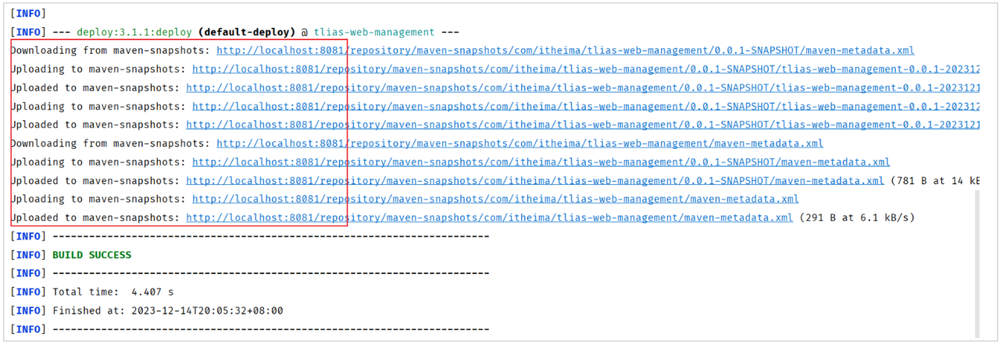

通过日志，我们可以看到，这几个模块打的jar包确实已经上传到了私服仓库中（由于当前我们的项目是SNAPSHOT版本，所以jar包是上传到了snapshot仓库中）。

那接下来，我们再来打开私服来看一下：

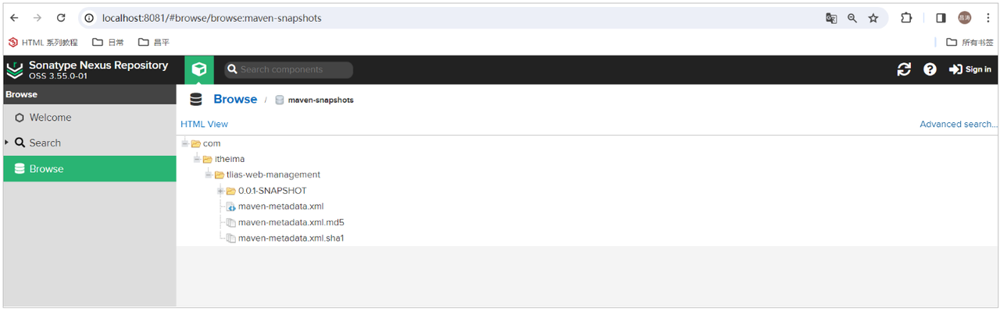

我们看到，我们项目中的这几个模块，在私服中都有了。 那接下来，当其他项目组的开发人员在项目中，就可以直接通过依赖的坐标，就可以完成引入对应的依赖，此时本地仓库没有，就会自动从私服仓库中下载。

**讲义提示**

> 备注说明：在真实的企业开发中，私服都是在远程服务器中的，并不是在本地的。这里我们只是为了方便演示。

## 复习速查与跟练验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| 配置优先级 | 属性源按优先级覆盖，同名键取高优先级值 | 只比较文件名，忽略 profile、环境变量和命令行 |
| `@Bean` | 在配置类中显式注册对象，适合第三方类型 | 误以为必须修改第三方源码添加 `@Component` |
| Bean 作用域 | singleton 默认单例，prototype 每次获取新实例 | 把 prototype 当成自动管理销毁的对象 |
| starter | 聚合依赖并带来约定版本 | 以为引入 starter 就等于执行了业务代码 |
| 自动配置 | 条件满足才注册默认 Bean，用户 Bean 可覆盖默认值 | 只看依赖，不检查条件注解和配置属性 |
| `@Conditional` | 按类、Bean、属性或表达式决定配置是否生效 | 把条件注解当成运行时业务判断 |
| 模块化 | 按职责拆分，公共模块被业务模块依赖 | 公共模块反向依赖业务模块造成环依赖 |
| `parent` | 继承 POM 配置和版本 | 以为 parent 会自动把所有依赖加入项目 |
| 聚合 | 根 POM 的 `modules` 一次构建多个模块 | 以为聚合必然等同于继承 |
| `dependencyManagement` | 统一依赖版本，子模块仍要声明依赖 | 只写管理段却忘记添加实际依赖 |
| 私服 | 代理、缓存和发布内部构件 | 把账号密码提交到 POM 或 Git |

### 跟练验收

1. 同时配置 properties、yaml、系统属性和命令行参数，启动后用 `/actuator/env` 或日志确认最终端口。
2. 用 `@Component`、`@Bean` 和 `@Import` 各注册一个 Bean，验证注入、名称和条件行为。
3. 在类路径中移除某个依赖，观察 `@ConditionalOnClass` 导致的自动配置变化；再添加同类型用户 Bean，验证 `@ConditionalOnMissingBean`。
4. 创建一个最小自定义 starter：配置属性、自动配置类、条件注解和测试应用各一份。
5. 将一个单体 Maven 工程拆成公共模块和业务模块，确认依赖方向、打包顺序和测试结果。
6. 在父 POM 中统一 Java、Spring Boot 和数据库驱动版本，用 `mvn help:effective-pom` 检查生效配置。
7. 执行 `mvn dependency:tree` 排查一个传递依赖冲突，并把构件发布到本地仓库或测试私服后由另一个模块下载。

### 自测问题

- 为什么 properties、yaml、环境变量和命令行参数可以同时存在？冲突时如何定位最终值？
- `@SpringBootApplication` 组合了哪些核心注解？自动配置为什么不会覆盖用户显式定义的 Bean？
- 起步依赖和自动配置分别解决什么问题？
- `parent`、`dependencyManagement` 和 `modules` 的职责有什么不同？
- 多模块项目如何避免公共模块与业务模块互相依赖？
- 私服代理、缓存和发布内部构件时，认证信息应放在哪里？